In [20]:
figure_dir = data_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

### 1.Data Loading and Quality Checks

#### (1) Load the Data and Inspect Its Structure

In [4]:
from pathlib import Path
import pandas as pd
from IPython.display import display

data_dir = Path(
    "/Users/gao.ptc/Desktop/Singapore🇸🇬/NTU/Trimeter 1/"
    "MH6805 Machine Learning/Group Project/KNN"
)

train_path = data_dir / "online_shoppers_train_fixed.csv"
test_path = data_dir / "online_shoppers_test_fixed.csv"

for path in [train_path, test_path]:
    if not path.is_file():
        raise FileNotFoundError(f"File not found: {path}")

train_raw = pd.read_csv(train_path)
test_raw = pd.read_csv(test_path)

train = train_raw.copy()
test = test_raw.copy()

print(f"Training set: {train.shape[0]:,} rows, {train.shape[1]} columns")
print(f"Test set: {test.shape[0]:,} rows, {test.shape[1]} columns")

print("\nIdentical column names and order:")
print(train.columns.equals(test.columns))

print("\nFirst five rows of the training set:")
display(train.head())

print("\nColumn data types:")
schema = pd.concat(
    [
        train.dtypes.rename("train_dtype"),
        test.dtypes.rename("test_dtype")
    ],
    axis=1
)
display(schema)

Training set: 9,764 rows, 18 columns
Test set: 2,441 rows, 18 columns

Identical column names and order:
True

First five rows of the training set:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
1,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
2,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
3,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
4,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.4,Feb,2,4,3,3,Returning_Visitor,False,False



Column data types:


,train_dtype,test_dtype
Administrative,int64,int64
Administrative_Duration,float64,float64
Informational,int64,int64
Informational_Duration,float64,float64
ProductRelated,int64,int64
ProductRelated_Duration,float64,float64
BounceRates,float64,float64
ExitRates,float64,float64
PageValues,float64,float64
SpecialDay,float64,float64


#### (2) Check Missing Values, Duplicates, and Cross-Set Overlap

In [7]:
missing_summary = pd.DataFrame({
    "train_missing": train.isna().sum(),
    "test_missing": test.isna().sum()
})

print("Missing values by column:")
display(missing_summary)

print("\nDuplicate rows within each dataset:")
print(f"Training set: {train.duplicated().sum():,}")
print(f"Test set: {test.duplicated().sum():,}")

shared_records = (
    train.drop_duplicates()
    .merge(
        test.drop_duplicates(),
        on=list(train.columns),
        how="inner"
    )
)

print("\nDistinct complete records shared by train and test:")
print(f"{len(shared_records):,}")

feature_columns = [
    column for column in train.columns
    if column != "Revenue"
]

shared_features = (
    train[feature_columns].drop_duplicates()
    .merge(
        test[feature_columns].drop_duplicates(),
        on=feature_columns,
        how="inner"
    )
)

print("\nDistinct predictor combinations shared by train and test:")
print(f"{len(shared_features):,}")

Missing values by column:


,train_missing,test_missing
Administrative,0,0
Administrative_Duration,0,0
Informational,0,0
Informational_Duration,0,0
ProductRelated,0,0
ProductRelated_Duration,0,0
BounceRates,0,0
ExitRates,0,0
PageValues,0,0
SpecialDay,0,0



Duplicate rows within each dataset:
Training set: 0
Test set: 0

Distinct complete records shared by train and test:
0

Distinct predictor combinations shared by train and test:
0


#### (3)Check Numerical Validity and Categorical Values

In [13]:
import numpy as np

numeric_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

count_features = [
    "Administrative",
    "Informational",
    "ProductRelated"
]

categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

validity_rows = []

for name, data in [("Train", train), ("Test", test)]:
    values = data[numeric_features]

    validity_rows.append({
        "Dataset": name,
        "Infinite values": int(np.isinf(values.to_numpy()).sum()),
        "Negative numerical values": int((values < 0).sum().sum()),
        "Non-integer page counts": int(
            (data[count_features] % 1 != 0).sum().sum()
        ),
        "BounceRates outside [0, 1]": int(
            (~data["BounceRates"].between(0, 1)).sum()
        ),
        "ExitRates outside [0, 1]": int(
            (~data["ExitRates"].between(0, 1)).sum()
        ),
        "SpecialDay outside [0, 1]": int(
            (~data["SpecialDay"].between(0, 1)).sum()
        ),
        "Invalid Revenue values": int(
            (~data["Revenue"].isin([True, False])).sum()
        ),
        "Invalid Weekend values": int(
            (~data["Weekend"].isin([True, False])).sum()
        )
    })

display(pd.DataFrame(validity_rows).set_index("Dataset").T)

print("\nNumerical ranges in the training set:")
display(train[numeric_features].agg(["min", "max"]).T)

category_rows = []

for column in categorical_features:
    train_values = set(train[column].dropna().unique())
    test_values = set(test[column].dropna().unique())

    category_rows.append({
        "Feature": column,
        "Training values": sorted(train_values, key=str),
        "Test-only values": sorted(test_values - train_values, key=str)
    })

print("\nCategorical values:")
display(pd.DataFrame(category_rows).set_index("Feature"))

Dataset,Train,Test
Infinite values,0,0
Negative numerical values,0,0
Non-integer page counts,0,0
"BounceRates outside [0, 1]",0,0
"ExitRates outside [0, 1]",0,0
"SpecialDay outside [0, 1]",0,0
Invalid Revenue values,0,0
Invalid Weekend values,0,0



Numerical ranges in the training set:


,min,max
Administrative,0.0,27.000000
Administrative_Duration,0.0,3398.750000
Informational,0.0,24.000000
Informational_Duration,0.0,2549.375000
ProductRelated,0.0,705.000000
ProductRelated_Duration,0.0,63973.522230
BounceRates,0.0,0.200000
ExitRates,0.0,0.200000
PageValues,0.0,361.763742
SpecialDay,0.0,1.000000



Categorical values:


,Training values,Test-only values
Feature,,
Month,"[Aug, Dec, Feb, Jul, June, Mar, May, Nov, Oct,...",[]
OperatingSystems,"[1, 2, 3, 4, 5, 6, 7, 8]",[]
Browser,"[1, 10, 11, 12, 13, 2, 3, 4, 5, 6, 7, 8, 9]",[]
Region,"[1, 2, 3, 4, 5, 6, 7, 8, 9]",[]
TrafficType,"[1, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 2,...",[]
VisitorType,"[New_Visitor, Other, Returning_Visitor]",[]
Weekend,"[False, True]",[]


### 2.EDA

#### (1) Target Class Distribution

,Outcome,Count,Percentage
0,No purchase,8238,84.37
1,Purchase,1526,15.63


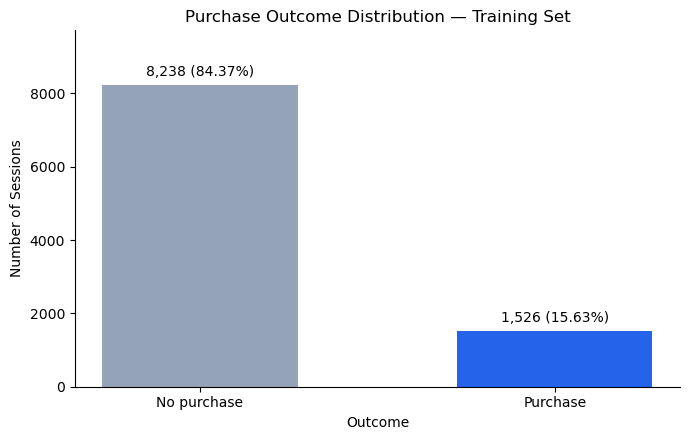

Training accuracy when predicting no purchase for every session: 84.37%


In [22]:
import matplotlib.pyplot as plt

class_counts = train["Revenue"].value_counts().reindex(
    [False, True], fill_value=0
)

class_summary = pd.DataFrame({
    "Outcome": ["No purchase", "Purchase"],
    "Count": class_counts.to_numpy(),
    "Percentage": class_counts.to_numpy() / len(train) * 100
})

display(class_summary.round({"Percentage": 2}))

fig, ax = plt.subplots(figsize=(7, 4.5))

bars = ax.bar(
    class_summary["Outcome"],
    class_summary["Count"],
    color=["#94A3B8", "#2563EB"],
    width=0.55
)

for bar, count, percentage in zip(
    bars,
    class_summary["Count"],
    class_summary["Percentage"]
):
    ax.annotate(
        f"{count:,} ({percentage:.2f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center"
    )

ax.set_title("Purchase Outcome Distribution — Training Set")
ax.set_xlabel("Outcome")
ax.set_ylabel("Number of Sessions")
ax.set_ylim(0, class_summary["Count"].max() * 1.18)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig.savefig(figure_dir / "01_target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

baseline_accuracy = (train["Revenue"] == False).mean()

print(
    f"Training accuracy when predicting no purchase for every session: "
    f"{baseline_accuracy:.2%}"
)

#### (2) Numerical Distributions and Zero Proportions

,count,mean,std,min,25%,50%,75%,95%,99%,max,zero_percentage,skewness
Administrative,9764.0,2.339,3.341,0.0,0.000,1.000,4.000,9.000,14.000,27.000,46.159,1.988
Administrative_Duration,9764.0,81.632,177.493,0.0,0.000,9.000,95.000,346.641,851.382,3398.750,47.245,5.610
Informational,9764.0,0.505,1.274,0.0,0.000,0.000,0.000,3.000,6.000,24.000,78.605,4.131
Informational_Duration,9764.0,35.258,143.094,0.0,0.000,0.000,0.000,201.825,728.571,2549.375,80.387,7.534
ProductRelated,9764.0,32.150,45.221,0.0,8.000,18.000,38.000,110.000,223.370,705.000,0.277,4.466
ProductRelated_Duration,9764.0,1209.732,1958.550,0.0,193.938,613.945,1470.685,4303.008,9030.088,63973.522,4.957,7.721
BounceRates,9764.0,0.020,0.045,0.0,0.000,0.003,0.017,0.133,0.200,0.200,45.381,3.185
ExitRates,9764.0,0.041,0.046,0.0,0.014,0.025,0.048,0.167,0.200,0.200,0.645,2.239
PageValues,9764.0,5.834,18.581,0.0,0.000,0.000,0.000,37.589,85.890,361.764,77.878,6.621
SpecialDay,9764.0,0.062,0.201,0.0,0.000,0.000,0.000,0.600,1.000,1.000,89.779,3.277


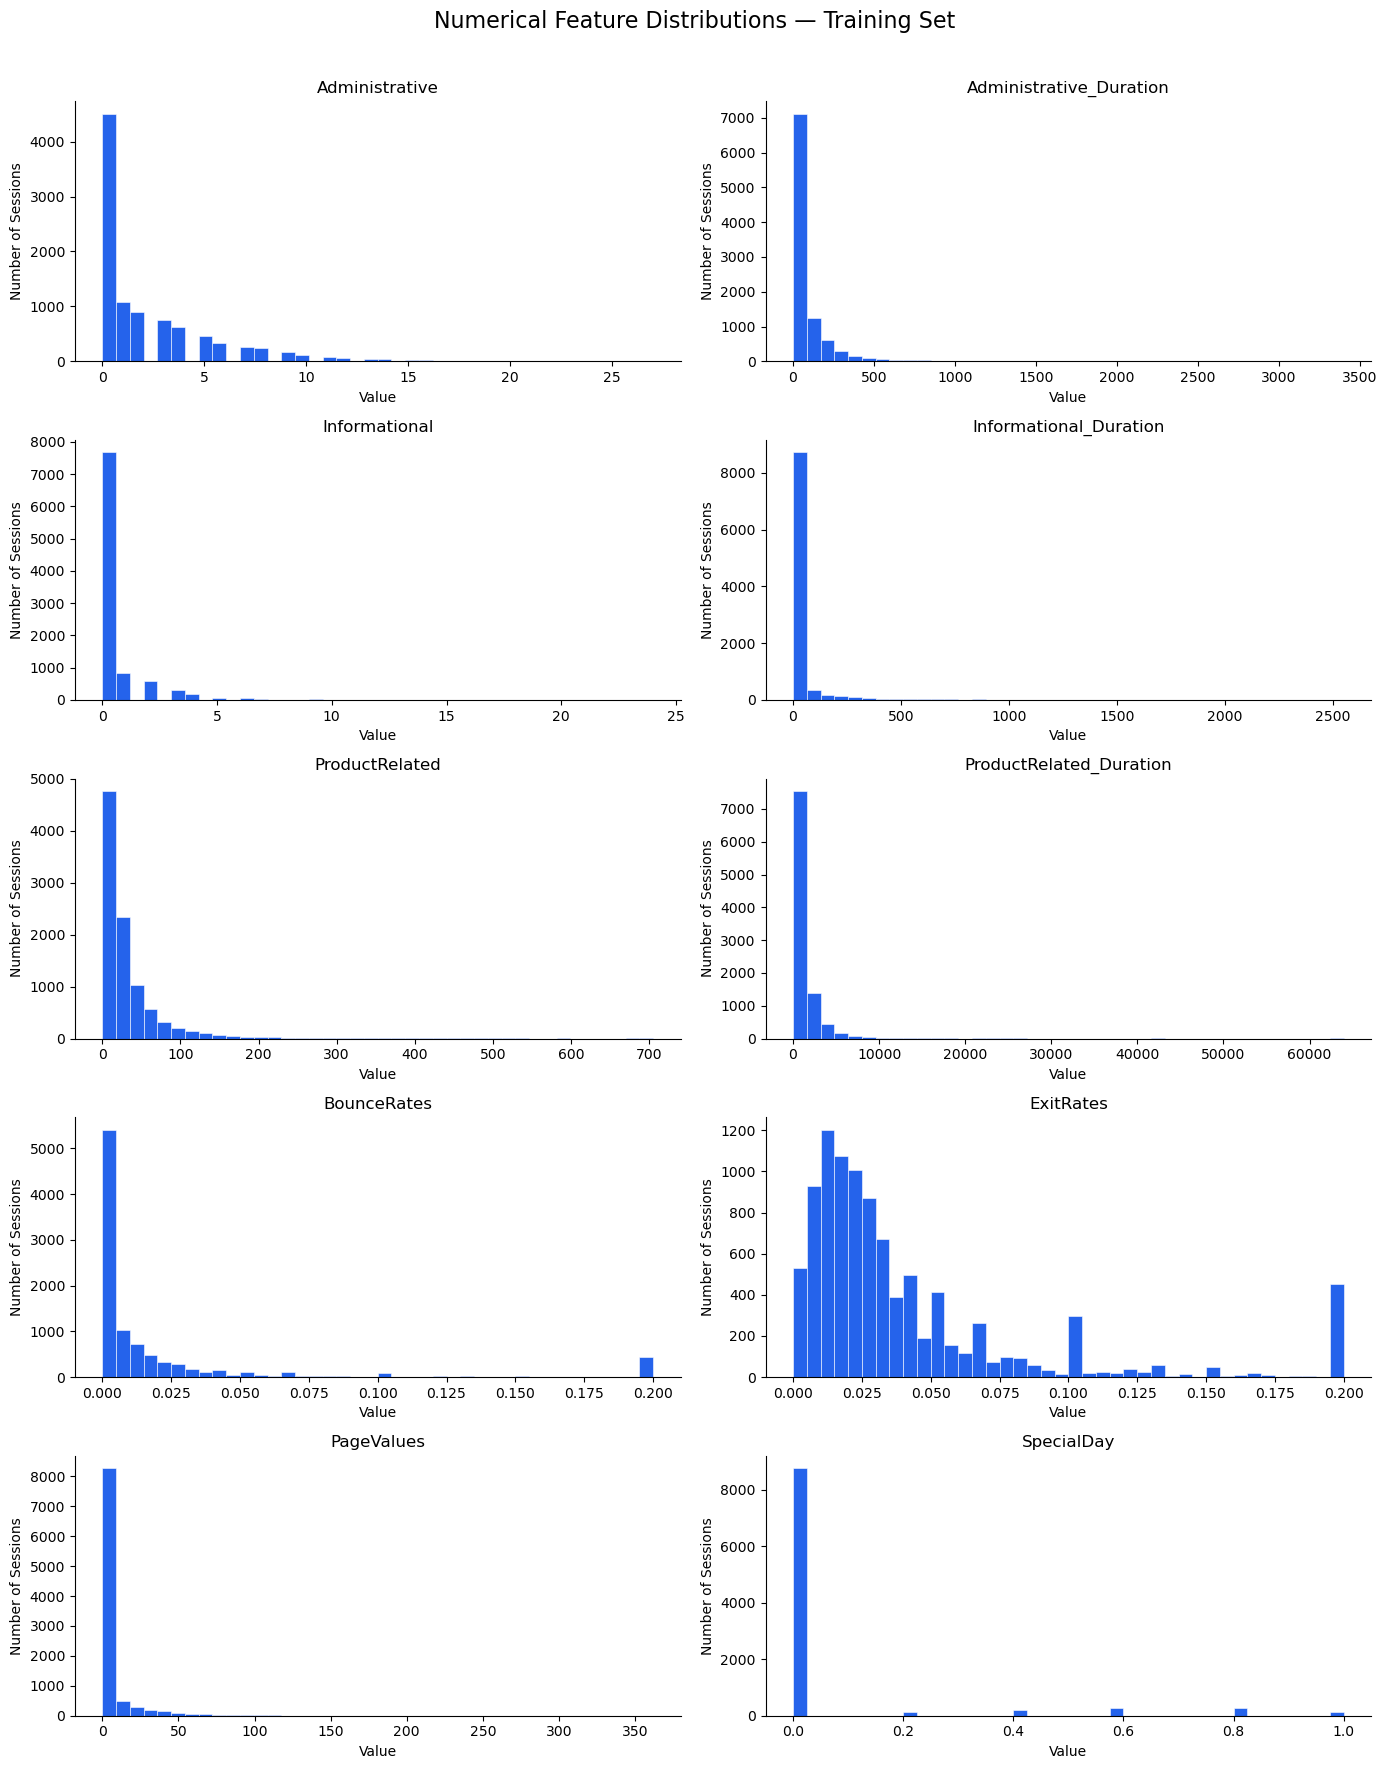

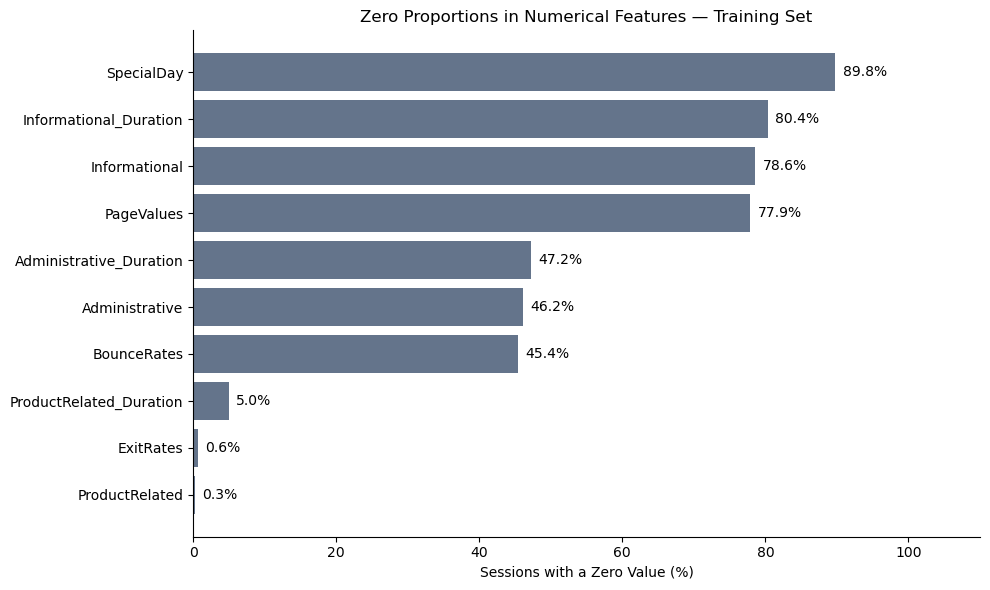

In [31]:
figure_dir = data_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

numeric_summary = train[numeric_features].describe(
    percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]
).T

numeric_summary["zero_percentage"] = (
    train[numeric_features].eq(0).mean() * 100
)
numeric_summary["skewness"] = train[numeric_features].skew()

display(numeric_summary.round(3))

fig, axes = plt.subplots(5, 2, figsize=(14, 18))

for ax, column in zip(axes.flat, numeric_features):
    ax.hist(
        train[column],
        bins=40,
        color="#2563EB",
        edgecolor="white",
        linewidth=0.4
    )
    ax.set_title(column)
    ax.set_xlabel("Value")
    ax.set_ylabel("Number of Sessions")
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Numerical Feature Distributions — Training Set",
    fontsize=16
)
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig(
    figure_dir / "02_numerical_distributions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

zero_percentages = numeric_summary["zero_percentage"].sort_values()

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    zero_percentages.index,
    zero_percentages.values,
    color="#64748B"
)

for bar, percentage in zip(bars, zero_percentages.values):
    ax.text(
        percentage + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{percentage:.1f}%",
        va="center"
    )

ax.set_title("Zero Proportions in Numerical Features — Training Set")
ax.set_xlabel("Sessions with a Zero Value (%)")
ax.set_xlim(0, 110)
ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(
    figure_dir / "03_zero_proportions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

#### (3) Numerical Features by Purchase Outcome

Count       Q1    Median        Q3  \
Feature                 Outcome                                           
Administrative          No purchase   8238    0.000     1.000     3.000   
                        Purchase      1526    0.000     2.000     5.000   
Administrative_Duration No purchase   8238    0.000     0.000    85.000   
                        Purchase      1526    0.000    52.517   150.875   
Informational           No purchase   8238    0.000     0.000     0.000   
                        Purchase      1526    0.000     0.000     1.000   
Informational_Duration  No purchase   8238    0.000     0.000     0.000   
                        Purchase      1526    0.000     0.000    17.000   
ProductRelated          No purchase   8238    7.000    16.000    35.000   
                        Purchase      1526   15.250    29.000    58.000   
ProductRelated_Duration No purchase   8238  159.925   528.417  1330.040   
                        Purchase      1526  553.125  1125.655  2296.751   
BounceRates             No purchase   8238    0.000     0.004     0.019   
                        Purchase      1526    0.000     0.000     0.007   
ExitRates               No purchase   8238    0.015     0.028     0.051   
                        Purchase      1526    0.009     0.016     0.025   

                                         Mean  Zero (%)  
Feature                 Outcome                          
Administrative          No purchase     2.146    49.612  
                        Purchase        3.385    27.523  
Administrative_Duration No purchase    74.054    50.619  
                        Purchase      122.542    29.030  
Informational           No purchase     0.456    80.505  
                        Purchase        0.769    68.349  
Informational_Duration  No purchase    31.216    82.156  
                        Purchase       57.081    70.839  
ProductRelated          No purchase    28.928     0.267  
                        Purchase       49.547     0.328  
ProductRelated_Duration No purchase  1076.569     5.778  
                        Purchase     1928.605     0.524  
BounceRates             No purchase     0.023    43.858  
                        Purchase        0.005    53.604  
ExitRates               No purchase     0.045     0.413  
                        Purchase        0.019     1.900

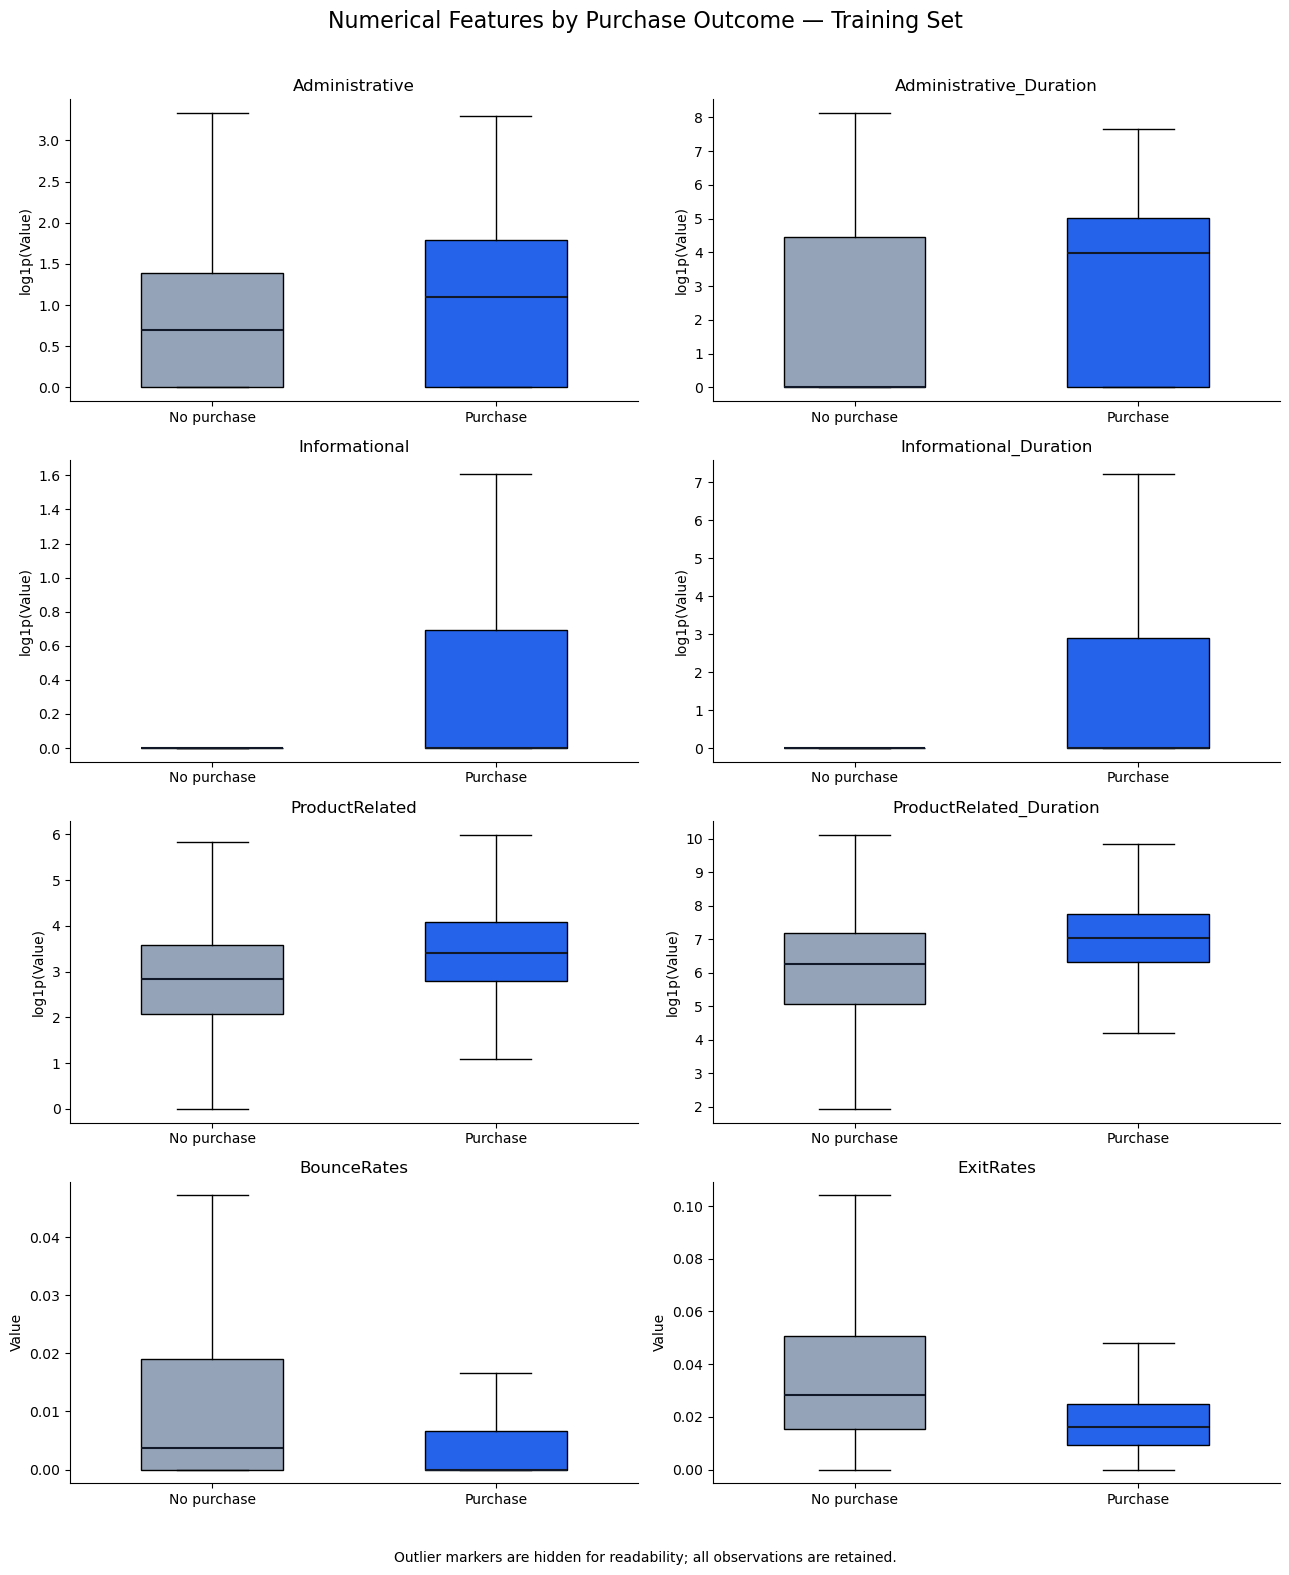

In [34]:
comparison_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates"
]

log_display_features = comparison_features[:6]

comparison_rows = []

for column in comparison_features:
    for outcome, label in [(False, "No purchase"), (True, "Purchase")]:
        values = train.loc[train["Revenue"] == outcome, column]

        comparison_rows.append({
            "Feature": column,
            "Outcome": label,
            "Count": len(values),
            "Q1": values.quantile(0.25),
            "Median": values.median(),
            "Q3": values.quantile(0.75),
            "Mean": values.mean(),
            "Zero (%)": values.eq(0).mean() * 100
        })

group_summary = pd.DataFrame(comparison_rows).set_index(
    ["Feature", "Outcome"]
)

display(group_summary.round(3))

figure_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(4, 2, figsize=(13, 16))

for ax, column in zip(axes.flat, comparison_features):
    groups = [
        train.loc[train["Revenue"] == outcome, column].to_numpy()
        for outcome in [False, True]
    ]

    if column in log_display_features:
        groups = [np.log1p(values) for values in groups]
        ylabel = "log1p(Value)"
    else:
        ylabel = "Value"

    boxes = ax.boxplot(
        groups,
        patch_artist=True,
        widths=0.5,
        showfliers=False,
        medianprops={"color": "#111827", "linewidth": 1.5}
    )

    for patch, color in zip(
        boxes["boxes"], ["#94A3B8", "#2563EB"]
    ):
        patch.set_facecolor(color)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(["No purchase", "Purchase"])
    ax.set_title(column)
    ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Numerical Features by Purchase Outcome — Training Set",
    fontsize=16
)
fig.text(
    0.5,
    0.01,
    "Outlier markers are hidden for readability; all observations are retained.",
    ha="center",
    fontsize=10
)
fig.tight_layout(rect=[0, 0.035, 1, 0.97])
fig.savefig(
    figure_dir / "04_numerical_features_by_outcome.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

#### (4) Purchase Rates by Category


Month


,Sessions,Purchases,Purchase rate (%)
Month,,,
Feb,143,2,1.40
Mar,1508,157,10.41
May,2630,283,10.76
June,235,25,10.64
Jul,348,49,14.08
Aug,357,65,18.21
Sep,357,64,17.93
Oct,445,97,21.80
Nov,2395,619,25.85



VisitorType


,Sessions,Purchases,Purchase rate (%)
VisitorType,,,
New_Visitor,1347,324,24.05
Other,67,12,17.91
Returning_Visitor,8350,1190,14.25



Weekend


...

,Sessions,Purchases,Purchase rate (%)
Region,,,
1,3763,612,16.26
2,930,153,16.45
3,1864,278,14.91
4,928,141,15.19
5,257,41,15.95
6,651,89,13.67
7,618,93,15.05
8,350,49,14.00
9,403,70,17.37



TrafficType


,Sessions,Purchases,Purchase rate (%)
TrafficType,,,
1,1898,216,11.38
2,3158,678,21.47
3,1606,147,9.15
4,844,128,15.17
5,200,41,20.50
6,363,43,11.85
7,29,10,34.48
8,281,74,26.33
9,37,4,10.81



SpecialDay


,Sessions,Purchases,Purchase rate (%)
SpecialDay,,,
0.0,8766,1465,16.71
0.2,135,10,7.41
0.4,198,11,5.56
0.6,273,24,8.79
0.8,265,10,3.77
1.0,127,6,4.72


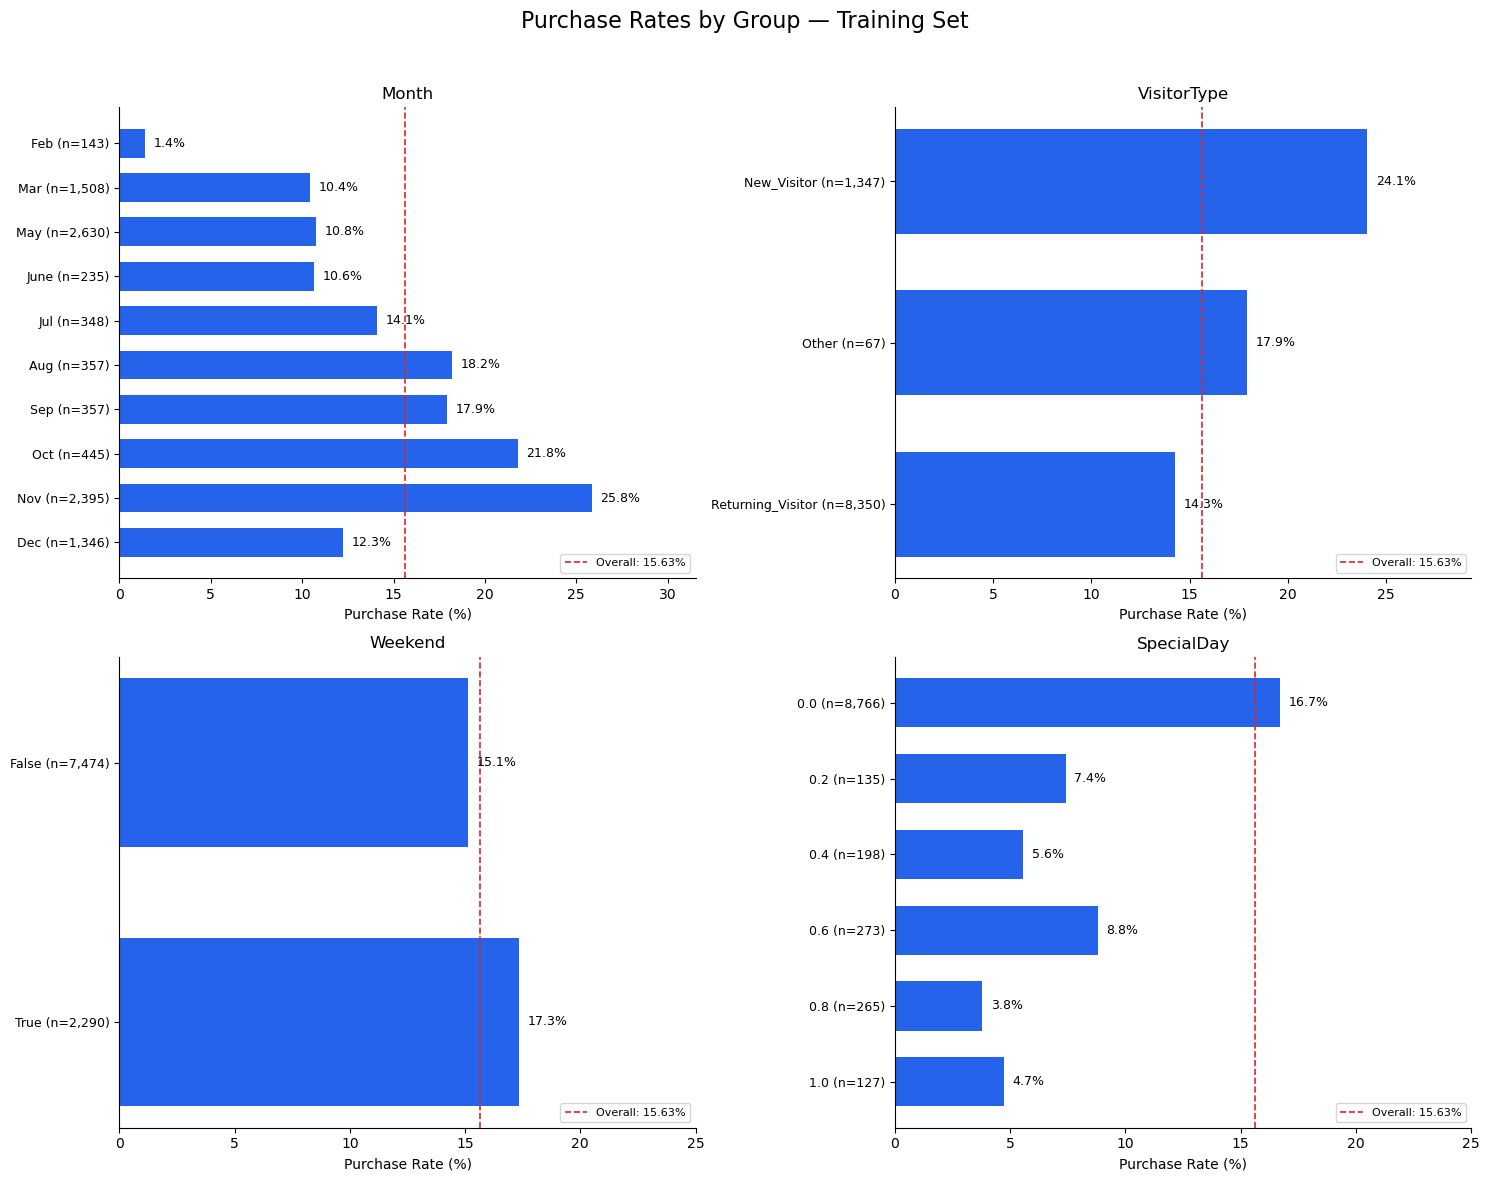

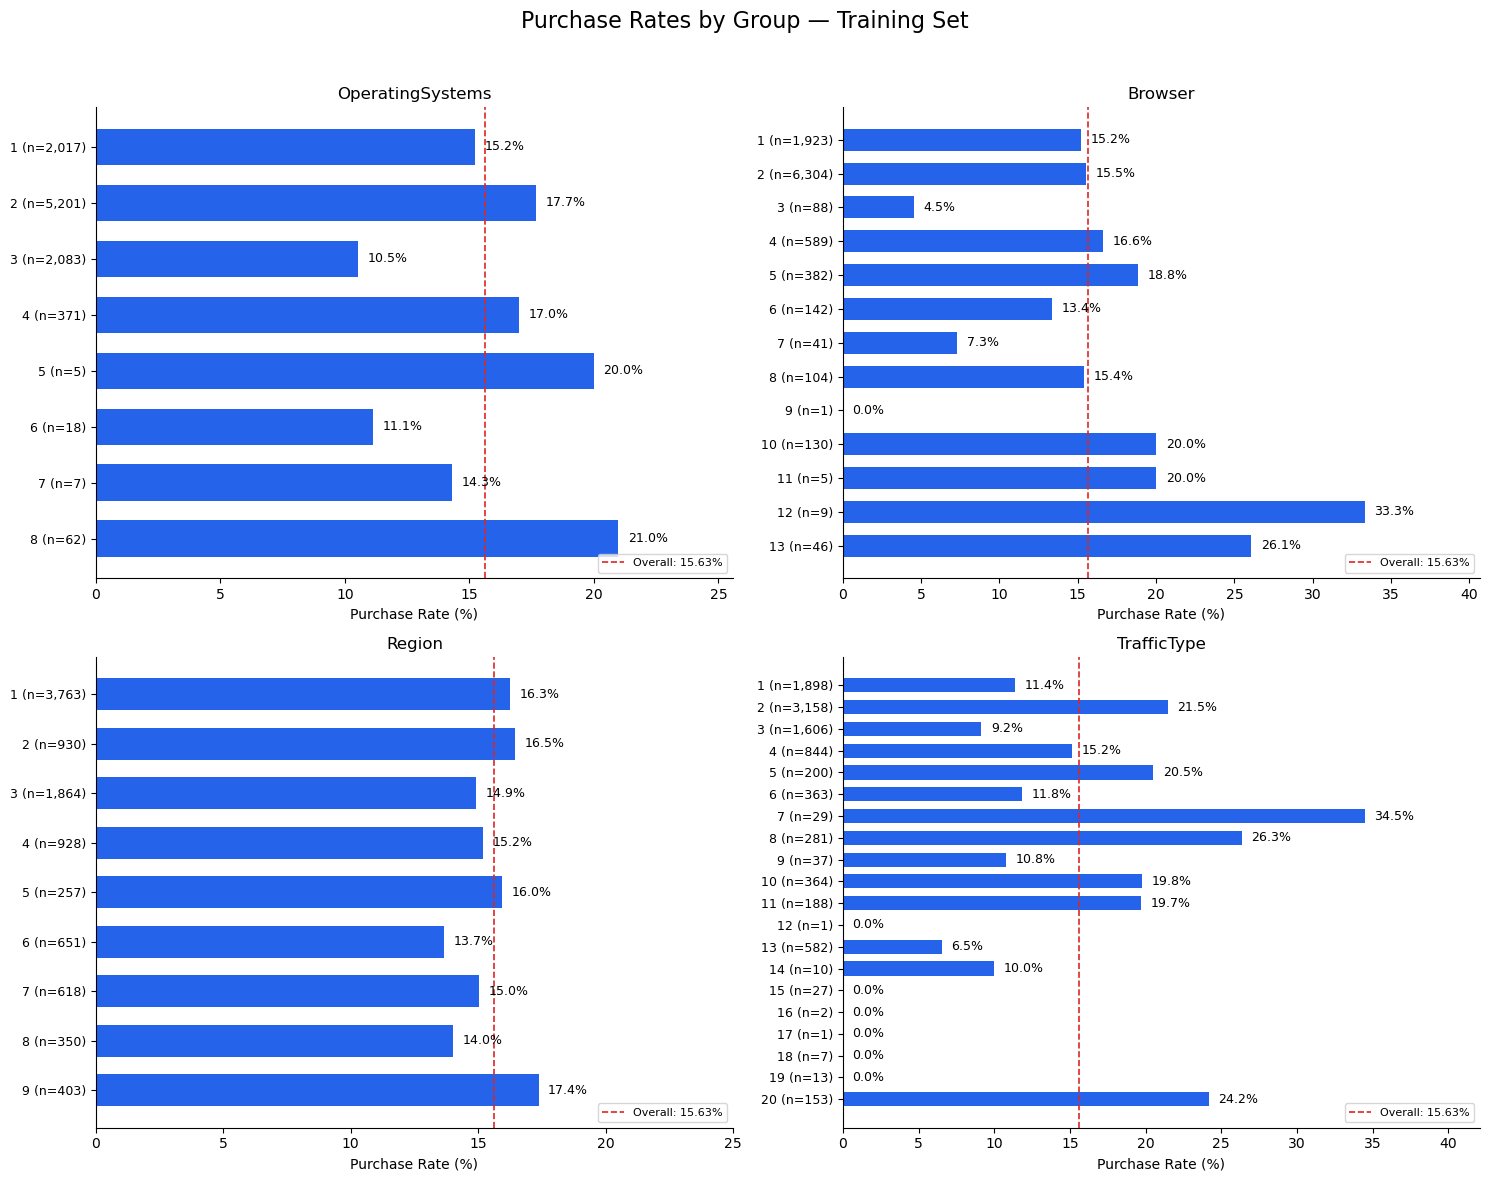

In [37]:
category_analysis_features = [
    "Month",
    "VisitorType",
    "Weekend",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "SpecialDay"
]

month_order = [
    "Jan", "Feb", "Mar", "Apr", "May", "June",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

category_summaries = {}

for column in category_analysis_features:
    summary = (
        train.groupby(column, observed=True)["Revenue"]
        .agg(Sessions="size", Purchases="sum")
    )

    if column == "Month":
        summary = summary.reindex(
            [month for month in month_order if month in summary.index]
        )
    else:
        summary = summary.sort_index()

    summary["Purchases"] = summary["Purchases"].astype(int)
    summary["Purchase rate (%)"] = (
        summary["Purchases"] / summary["Sessions"] * 100
    )

    category_summaries[column] = summary

    print(f"\n{column}")
    display(summary.round(2))

overall_purchase_rate = train["Revenue"].mean() * 100

figure_dir.mkdir(parents=True, exist_ok=True)

for filename, columns in [
    (
        "05_purchase_rates_by_category.png",
        ["Month", "VisitorType", "Weekend", "SpecialDay"]
    ),
    (
        "06_purchase_rates_by_category_codes.png",
        ["OperatingSystems", "Browser", "Region", "TrafficType"]
    )
]:
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    for ax, column in zip(axes.flat, columns):
        summary = category_summaries[column]
        positions = np.arange(len(summary))

        bars = ax.barh(
            positions,
            summary["Purchase rate (%)"],
            color="#2563EB",
            height=0.65
        )

        labels = [
            f"{category} (n={int(count):,})"
            for category, count in zip(
                summary.index,
                summary["Sessions"]
            )
        ]

        ax.set_yticks(positions)
        ax.set_yticklabels(labels, fontsize=9)
        ax.invert_yaxis()

        ax.axvline(
            overall_purchase_rate,
            color="#DC2626",
            linestyle="--",
            linewidth=1.2,
            label=f"Overall: {overall_purchase_rate:.2f}%"
        )

        upper_limit = min(
            110,
            max(
                25,
                summary["Purchase rate (%)"].max() * 1.22,
                overall_purchase_rate * 1.3
            )
        )

        ax.set_xlim(0, upper_limit)

        for bar, rate in zip(
            bars,
            summary["Purchase rate (%)"]
        ):
            ax.text(
                rate + upper_limit * 0.015,
                bar.get_y() + bar.get_height() / 2,
                f"{rate:.1f}%",
                va="center",
                fontsize=9
            )

        ax.set_title(column)
        ax.set_xlabel("Purchase Rate (%)")
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(loc="lower right", fontsize=8)

    fig.suptitle(
        "Purchase Rates by Group — Training Set",
        fontsize=16
    )
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(
        figure_dir / filename,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

#### (5) Correlation Between Numerical Predictors

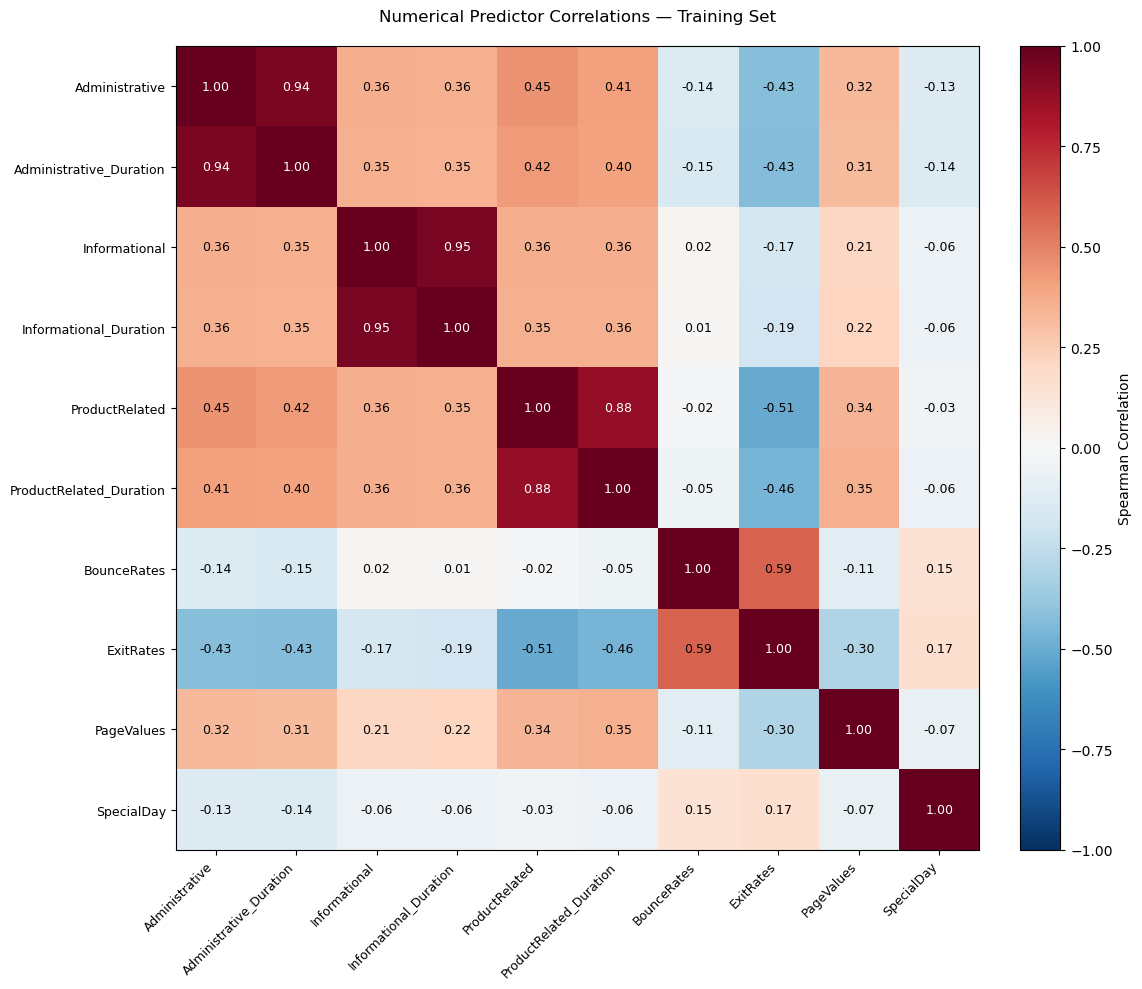

Top 10 predictor pairs by absolute Spearman correlation:


,Feature 1,Feature 2,Spearman correlation,Absolute correlation
0,Informational,Informational_Duration,0.952,0.952
1,Administrative,Administrative_Duration,0.940,0.940
2,ProductRelated,ProductRelated_Duration,0.877,0.877
3,BounceRates,ExitRates,0.587,0.587
4,ProductRelated,ExitRates,-0.506,0.506
5,ProductRelated_Duration,ExitRates,-0.461,0.461
6,Administrative,ProductRelated,0.453,0.453
7,Administrative_Duration,ExitRates,-0.434,0.434
8,Administrative,ExitRates,-0.428,0.428
9,Administrative_Duration,ProductRelated,0.424,0.424


In [40]:
spearman_corr = train[numeric_features].corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 10))

heatmap = ax.imshow(
    spearman_corr.to_numpy(),
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

positions = np.arange(len(numeric_features))

ax.set_xticks(positions)
ax.set_yticks(positions)
ax.set_xticklabels(
    numeric_features,
    rotation=45,
    ha="right",
    fontsize=9
)
ax.set_yticklabels(numeric_features, fontsize=9)

for row in range(len(numeric_features)):
    for col in range(len(numeric_features)):
        value = spearman_corr.iloc[row, col]

        ax.text(
            col,
            row,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if abs(value) >= 0.6 else "black",
            fontsize=9
        )

colorbar = fig.colorbar(heatmap, ax=ax, fraction=0.046, pad=0.04)
colorbar.set_label("Spearman Correlation")

ax.set_title("Numerical Predictor Correlations — Training Set", pad=18)

fig.tight_layout()
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(
    figure_dir / "07_spearman_correlations.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

pair_rows = []

for row in range(len(numeric_features)):
    for col in range(row + 1, len(numeric_features)):
        value = spearman_corr.iloc[row, col]

        pair_rows.append({
            "Feature 1": numeric_features[row],
            "Feature 2": numeric_features[col],
            "Spearman correlation": value,
            "Absolute correlation": abs(value)
        })

correlation_pairs = (
    pd.DataFrame(pair_rows)
    .sort_values("Absolute correlation", ascending=False)
    .reset_index(drop=True)
)

print("Top 10 predictor pairs by absolute Spearman correlation:")
display(correlation_pairs.head(10).round(3))

#### (6) PageValues and Purchase Outcomes

Purchase rates for zero and positive PageValues:


,Sessions,Purchases,Purchase rate (%)
PageValues group,,,
Zero,7604,308,4.05
Positive,2160,1218,56.39



Purchase rates by PageValues band:


,Sessions,Purchases,Purchase rate (%)
PageValues band,,,
0,7604,308,4.05
"(0, 1]",54,11,20.37
"(1, 5]",307,115,37.46
"(5, 20]",884,423,47.85
>20,915,669,73.11



Spearman correlation between PageValues and Revenue: 0.623


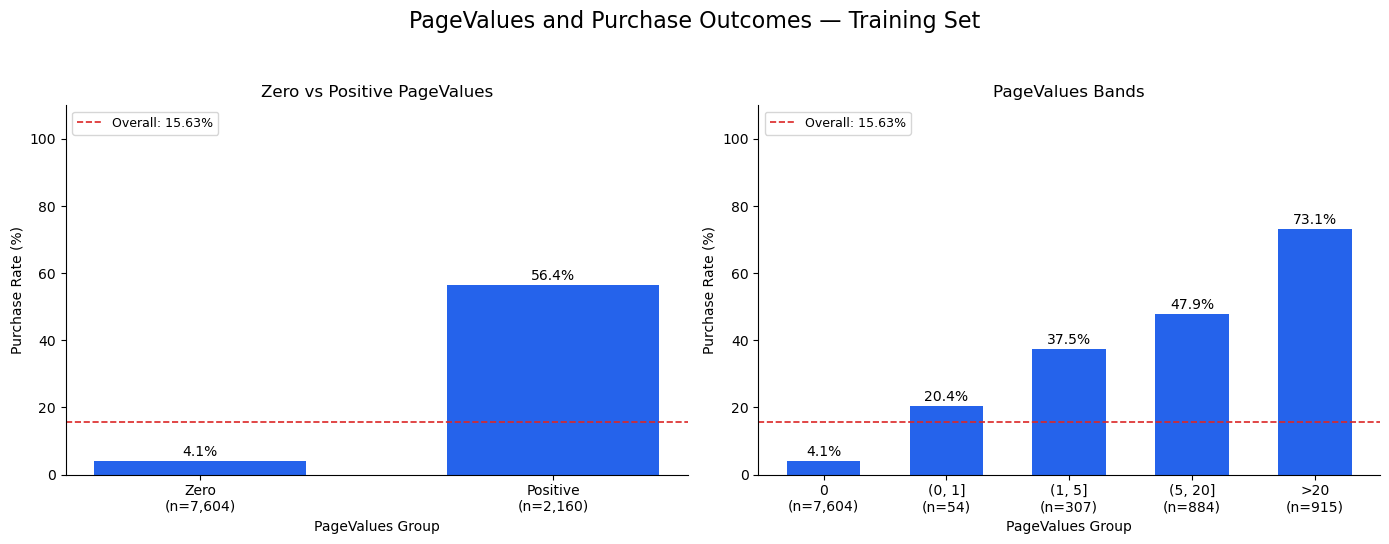

In [43]:
pagevalues_eda = train[["PageValues", "Revenue"]].copy()

pagevalues_eda["PageValues group"] = np.where(
    pagevalues_eda["PageValues"].eq(0),
    "Zero",
    "Positive"
)

pagevalues_eda["PageValues band"] = pd.cut(
    pagevalues_eda["PageValues"],
    bins=[-np.inf, 0, 1, 5, 20, np.inf],
    labels=["0", "(0, 1]", "(1, 5]", "(5, 20]", ">20"],
    right=True
)

pagevalues_group_summary = (
    pagevalues_eda.groupby("PageValues group")["Revenue"]
    .agg(Sessions="size", Purchases="sum")
    .reindex(["Zero", "Positive"])
)

pagevalues_band_summary = (
    pagevalues_eda.groupby(
        "PageValues band",
        observed=False
    )["Revenue"]
    .agg(Sessions="size", Purchases="sum")
)

for summary in [
    pagevalues_group_summary,
    pagevalues_band_summary
]:
    summary["Purchase rate (%)"] = (
        summary["Purchases"]
        .div(summary["Sessions"].replace(0, np.nan))
        * 100
    )

print("Purchase rates for zero and positive PageValues:")
display(pagevalues_group_summary.round(2))

print("\nPurchase rates by PageValues band:")
display(pagevalues_band_summary.round(2))

pagevalues_correlation = pagevalues_eda["PageValues"].corr(
    pagevalues_eda["Revenue"].astype(int),
    method="spearman"
)

print(
    "\nSpearman correlation between PageValues and Revenue: "
    f"{pagevalues_correlation:.3f}"
)

overall_purchase_rate = train["Revenue"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, summary, title in zip(
    axes,
    [pagevalues_group_summary, pagevalues_band_summary],
    ["Zero vs Positive PageValues", "PageValues Bands"]
):
    positions = np.arange(len(summary))

    bars = ax.bar(
        positions,
        summary["Purchase rate (%)"],
        color="#2563EB",
        width=0.6
    )

    ax.set_xticks(positions)
    ax.set_xticklabels([
        f"{category}\n(n={int(count):,})"
        for category, count in zip(
            summary.index,
            summary["Sessions"]
        )
    ])

    for bar, rate in zip(
        bars,
        summary["Purchase rate (%)"]
    ):
        if pd.notna(rate):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                rate + 1.5,
                f"{rate:.1f}%",
                ha="center",
                fontsize=10
            )

    ax.axhline(
        overall_purchase_rate,
        color="#DC2626",
        linestyle="--",
        linewidth=1.2,
        label=f"Overall: {overall_purchase_rate:.2f}%"
    )

    ax.set_title(title)
    ax.set_xlabel("PageValues Group")
    ax.set_ylabel("Purchase Rate (%)")
    ax.set_ylim(0, 110)
    ax.set_yticks([0, 20, 40, 60, 80, 100])
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper left", fontsize=9)

fig.suptitle(
    "PageValues and Purchase Outcomes — Training Set",
    fontsize=16
)
fig.tight_layout(rect=[0, 0, 1, 0.94])

figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(
    figure_dir / "08_pagevalues_purchase_rates.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### 3. Build a preprocessing pipeline

#### (1) Define Features and Target

In [46]:
SEED = 6805
TARGET = "Revenue"

categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

main_numeric_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "SpecialDay"
]

log_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration"
]

remaining_numeric_features = [
    column for column in main_numeric_features
    if column not in log_features
]

main_features = main_numeric_features + categorical_features

X_train = train[main_features].copy()
y_train = train[TARGET].astype(int).copy()

X_test = test[main_features].copy()
y_test = test[TARGET].astype(int).copy()

assert TARGET not in X_train.columns
assert "PageValues" not in X_train.columns
assert X_train.columns.equals(X_test.columns)
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert len(main_features) == len(set(main_features)) == 16
assert set(y_train.unique()) == {0, 1}
assert set(y_test.unique()).issubset({0, 1})

feature_roles = pd.DataFrame({
    "Feature": main_features,
    "Type": (
        ["Numerical"] * len(main_numeric_features)
        + ["Categorical"] * len(categorical_features)
    ),
    "Candidate log1p transformation": [
        column in log_features for column in main_features
    ]
})

display(feature_roles)

print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")
print(f"\nCross-validation seed: {SEED}")
print("Target encoding: 0 = No purchase, 1 = Purchase")
print("PageValues excluded from primary model inputs.")
print("Feature and target checks passed.")

,Feature,Type,Candidate log1p transformation
0,Administrative,Numerical,True
1,Administrative_Duration,Numerical,True
2,Informational,Numerical,True
3,Informational_Duration,Numerical,True
4,ProductRelated,Numerical,True
5,ProductRelated_Duration,Numerical,True
6,BounceRates,Numerical,False
7,ExitRates,Numerical,False
8,SpecialDay,Numerical,False
9,Month,Categorical,False


X_train shape: (9764, 16)
y_train shape: (9764,)
X_test shape: (2441, 16)
y_test shape: (2441,)

Cross-validation seed: 6805
Target encoding: 0 = No purchase, 1 = Purchase
PageValues excluded from primary model inputs.
Feature and target checks passed.


#### (2) Build Candidate KNN Pipelines

In [49]:
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer
)
from sklearn.neighbors import KNeighborsClassifier

preprocessor_standard = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            main_numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="drop",
    sparse_threshold=0
)

log_numeric_pipeline = Pipeline(
    steps=[
        (
            "log1p",
            FunctionTransformer(
                np.log1p,
                feature_names_out="one-to-one"
            )
        ),
        ("scaler", StandardScaler())
    ]
)

preprocessor_log = ColumnTransformer(
    transformers=[
        (
            "log_numeric",
            log_numeric_pipeline,
            log_features
        ),
        (
            "other_numeric",
            StandardScaler(),
            remaining_numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="drop",
    sparse_threshold=0
)

knn_standard = Pipeline(
    steps=[
        ("preprocessor", preprocessor_standard),
        (
            "knn",
            KNeighborsClassifier(
                n_neighbors=5,
                weights="uniform",
                metric="minkowski",
                p=2,
                algorithm="brute",
                n_jobs=1
            )
        )
    ]
)

knn_log = Pipeline(
    steps=[
        ("preprocessor", preprocessor_log),
        (
            "knn",
            KNeighborsClassifier(
                n_neighbors=5,
                weights="uniform",
                metric="minkowski",
                p=2,
                algorithm="brute",
                n_jobs=1
            )
        )
    ]
)

candidate_pipelines = {
    "Standard": knn_standard,
    "Log1p + Standard": knn_log
}

print(f"scikit-learn version: {sklearn.__version__}")

for name, pipeline in candidate_pipelines.items():
    print(f"\n{name}")
    print(f"Steps: list({list(pipeline.named_steps)})")
    print(f"Neighbors: {pipeline.get_params()['knn__n_neighbors']}")
    print(f"Weights: {pipeline.get_params()['knn__weights']}")
    print(f"Minkowski p: {pipeline.get_params()['knn__p']}")

print("\nBoth pipelines are defined and remain unfitted.")

scikit-learn version: 1.5.1

Standard
Steps: list(['preprocessor', 'knn'])
Neighbors: 5
Weights: uniform
Minkowski p: 2

Log1p + Standard
Steps: list(['preprocessor', 'knn'])
Neighbors: 5
Weights: uniform
Minkowski p: 2

Both pipelines are defined and remain unfitted.


### 4. Cross-validation Design

In [52]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

cv_splits = list(cv.split(X_train, y_train))

fold_rows = []
validation_counts = np.zeros(len(X_train), dtype=int)
validation_fold = np.zeros(len(X_train), dtype=int)

for fold, (train_idx, valid_idx) in enumerate(cv_splits, start=1):
    assert len(np.intersect1d(train_idx, valid_idx)) == 0
    assert len(train_idx) + len(valid_idx) == len(X_train)

    validation_counts[valid_idx] += 1
    validation_fold[valid_idx] = fold

    train_labels = y_train.iloc[train_idx]
    valid_labels = y_train.iloc[valid_idx]

    fold_rows.append({
        "Fold": fold,
        "Training sessions": len(train_idx),
        "Validation sessions": len(valid_idx),
        "Training purchases": int(train_labels.sum()),
        "Validation purchases": int(valid_labels.sum()),
        "Training purchase rate (%)": train_labels.mean() * 100,
        "Validation purchase rate (%)": valid_labels.mean() * 100
    })

assert np.all(validation_counts == 1)

fold_summary = pd.DataFrame(fold_rows).set_index("Fold")
display(fold_summary.round(3))

results_dir = data_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

fold_assignments = pd.DataFrame({
    "training_row_position": np.arange(len(X_train)),
    "validation_fold": validation_fold
})

fold_assignments.to_csv(
    results_dir / "cv_fold_assignments_seed6805.csv",
    index=False
)

print("Five stratified folds created.")
print("No overlap between training and validation rows within each fold.")
print("Every training observation appears in exactly one validation fold.")
print("The fixed test set was not used.")
print(
    f"Fold assignments saved to: "
    f"{results_dir / 'cv_fold_assignments_seed6805.csv'}"
)

,Training sessions,Validation sessions,Training purchases,Validation purchases,Training purchase rate (%),Validation purchase rate (%)
Fold,,,,,,
1,7811,1953,1221,305,15.632,15.617
2,7811,1953,1221,305,15.632,15.617
3,7811,1953,1221,305,15.632,15.617
4,7811,1953,1220,306,15.619,15.668
5,7812,1952,1221,305,15.630,15.625


Five stratified folds created.
No overlap between training and validation rows within each fold.
Every training observation appears in exactly one validation fold.
The fixed test set was not used.
Fold assignments saved to: /Users/gao.ptc/Desktop/Singapore🇸🇬/NTU/Trimeter 1/MH6805 Machine Learning/Group Project/KNN/results/cv_fold_assignments_seed6805.csv


### 5. Baseline and Initial KNN Evaluation

In [54]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.model_selection import cross_validate

scoring = {
    "AP": "average_precision",
    "ROC_AUC": "roc_auc",
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall": make_scorer(recall_score, zero_division=0),
    "F1": make_scorer(f1_score, zero_division=0),
    "Accuracy": "accuracy"
}

baseline_models = {
    "All-negative baseline": DummyClassifier(
        strategy="constant",
        constant=0
    ),
    "KNN - Standard": knn_standard,
    "KNN - Log1p + Standard": knn_log
}

baseline_rows = []

for model_name, model in baseline_models.items():
    print(f"Evaluating: {model_name}", flush=True)

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv_splits,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    for fold in range(len(cv_splits)):
        row = {
            "Model": model_name,
            "Fold": fold + 1
        }

        for metric in scoring:
            row[metric] = scores[f"test_{metric}"][fold]

        baseline_rows.append(row)

baseline_fold_results = pd.DataFrame(baseline_rows)

baseline_summary = (
    baseline_fold_results
    .groupby("Model", sort=False)[list(scoring)]
    .agg(["mean", "std"])
)

baseline_display = pd.DataFrame(
    index=baseline_summary.index
)

for metric in scoring:
    baseline_display[metric] = (
        baseline_summary[(metric, "mean")].map("{:.4f}".format)
        + " ± "
        + baseline_summary[(metric, "std")].map("{:.4f}".format)
    )

print("\nResults by fold:")
display(baseline_fold_results.round(4))

print("\nCross-validation mean ± sample standard deviation:")
display(baseline_display)

results_dir.mkdir(parents=True, exist_ok=True)

baseline_fold_results.to_csv(
    results_dir / "baseline_cv_fold_results.csv",
    index=False
)

summary_export = baseline_summary.copy()
summary_export.columns = [
    f"{metric}_{statistic}"
    for metric, statistic in summary_export.columns
]

summary_export.to_csv(
    results_dir / "baseline_cv_summary.csv"
)

print("\nBaseline evaluation completed. The fixed test set was not used.")

Evaluating: All-negative baseline
Evaluating: KNN - Standard
Evaluating: KNN - Log1p + Standard

Results by fold:


,Model,Fold,AP,ROC_AUC,Precision,Recall,F1,Accuracy
0,All-negative baseline,1,0.1562,0.5000,0.0000,0.0000,0.0000,0.8438
1,All-negative baseline,2,0.1562,0.5000,0.0000,0.0000,0.0000,0.8438
2,All-negative baseline,3,0.1562,0.5000,0.0000,0.0000,0.0000,0.8438
3,All-negative baseline,4,0.1567,0.5000,0.0000,0.0000,0.0000,0.8433
4,All-negative baseline,5,0.1562,0.5000,0.0000,0.0000,0.0000,0.8438
5,KNN - Standard,1,0.2189,0.6242,0.3228,0.1344,0.1898,0.8208
6,KNN - Standard,2,0.2418,0.6615,0.3520,0.1443,0.2047,0.8249
7,KNN - Standard,3,0.2549,0.6659,0.3520,0.1443,0.2047,0.8249
8,KNN - Standard,4,0.2491,0.6426,0.4016,0.1601,0.2290,0.8310
9,KNN - Standard,5,0.2296,0.6369,0.3456,0.1541,0.2132,0.8222



Cross-validation mean ± sample standard deviation:


,AP,ROC_AUC,Precision,Recall,F1,Accuracy
Model,,,,,,
All-negative baseline,0.1563 ± 0.0002,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.8437 ± 0.0002
KNN - Standard,0.2389 ± 0.0146,0.6462 ± 0.0174,0.3548 ± 0.0288,0.1474 ± 0.0099,0.2082 ± 0.0143,0.8248 ± 0.0039
KNN - Log1p + Standard,0.2533 ± 0.0197,0.6694 ± 0.0216,0.3584 ± 0.0461,0.1566 ± 0.0181,0.2175 ± 0.0238,0.8239 ± 0.0080



Baseline evaluation completed. The fixed test set was not used.


### 6.KNN Hyperparameter Tuning

#### (1)

In [56]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV

search_pipeline = clone(knn_standard)

param_grid = {
    "preprocessor": [
        clone(preprocessor_standard),
        clone(preprocessor_log)
    ],
    "knn__n_neighbors": [5, 15, 31, 61, 101],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]
}

knn_search = GridSearchCV(
    estimator=search_pipeline,
    param_grid=param_grid,
    scoring=scoring,
    refit="AP",
    cv=cv_splits,
    n_jobs=2,
    pre_dispatch=2,
    return_train_score=False,
    error_score="raise",
    verbose=1
)

knn_search.fit(X_train, y_train)

search_results = pd.DataFrame(knn_search.cv_results_)

def get_preprocessing_name(preprocessor):
    names = [
        name for name, transformer, columns
        in preprocessor.transformers
    ]
    return "Log1p + Standard" if "log_numeric" in names else "Standard"

tuning_results = pd.DataFrame({
    "Candidate": search_results.index,
    "AP rank": search_results["rank_test_AP"],
    "Preprocessing": [
        get_preprocessing_name(preprocessor)
        for preprocessor in search_results["param_preprocessor"]
    ],
    "Neighbors": search_results["param_knn__n_neighbors"].astype(int),
    "Weights": search_results["param_knn__weights"].astype(str),
    "Distance": search_results["param_knn__p"].map({
        1: "Manhattan",
        2: "Euclidean"
    })
})

for metric in scoring:
    fold_columns = [
        f"split{fold}_test_{metric}"
        for fold in range(len(cv_splits))
    ]

    tuning_results[f"{metric} mean"] = (
        search_results[f"mean_test_{metric}"]
    )
    tuning_results[f"{metric} SD"] = (
        search_results[fold_columns].std(axis=1, ddof=1)
    )

tuning_results = tuning_results.sort_values(
    ["AP rank", "Candidate"],
    kind="stable"
).reset_index(drop=True)

best_knn = knn_search.best_estimator_

selected_configuration = tuning_results.loc[
    tuning_results["Candidate"] == knn_search.best_index_
].copy()

print("\nTop 10 configurations ranked by mean AP:")
display(
    tuning_results[
        [
            "AP rank",
            "Preprocessing",
            "Neighbors",
            "Weights",
            "Distance",
            "AP mean",
            "AP SD",
            "ROC_AUC mean",
            "Precision mean",
            "Recall mean",
            "F1 mean",
            "Accuracy mean"
        ]
    ].head(10).round(4)
)

print("\nSelected configuration:")
display(selected_configuration.round(4))

results_dir.mkdir(parents=True, exist_ok=True)

tuning_results.to_csv(
    results_dir / "knn_grid_search_results.csv",
    index=False
)

selected_configuration.to_csv(
    results_dir / "knn_selected_configuration.csv",
    index=False
)

fold_score_columns = [
    f"split{fold}_test_{metric}"
    for metric in scoring
    for fold in range(len(cv_splits))
]

search_results[fold_score_columns].rename_axis(
    "Candidate"
).to_csv(
    results_dir / "knn_grid_search_fold_scores.csv"
)

print("\nGrid search completed.")
print("Selection metric: mean cross-validation AP.")
print(f"Best mean cross-validation AP: {knn_search.best_score_:.4f}")
print("The selected pipeline has been refitted on the full training set.")
print("The fixed test set was not used.")

Fitting 5 folds for each of 40 candidates, totalling 200 fits

Top 10 configurations ranked by mean AP:


,AP rank,Preprocessing,Neighbors,Weights,Distance,AP mean,AP SD,ROC_AUC mean,Precision mean,Recall mean,F1 mean,Accuracy mean
0,1,Log1p + Standard,101,distance,Manhattan,0.3481,0.0259,0.7506,0.7643,0.0079,0.0155,0.8444
1,2,Log1p + Standard,61,distance,Manhattan,0.3469,0.0273,0.7461,0.6608,0.0288,0.0550,0.8458
2,3,Log1p + Standard,101,distance,Euclidean,0.3413,0.0259,0.7449,0.7000,0.0039,0.0078,0.8442
3,4,Log1p + Standard,101,uniform,Manhattan,0.3393,0.0244,0.7493,0.6333,0.0046,0.0091,0.8441
4,5,Log1p + Standard,61,uniform,Manhattan,0.3362,0.0248,0.7451,0.6095,0.0190,0.0367,0.8447
5,6,Standard,101,distance,Manhattan,0.3348,0.0251,0.7420,0.6400,0.0046,0.0091,0.8437
6,7,Log1p + Standard,61,distance,Euclidean,0.3338,0.0257,0.7403,0.5989,0.0144,0.0281,0.8443
7,8,Standard,61,distance,Manhattan,0.3332,0.0218,0.7391,0.5842,0.0151,0.0292,0.8438
8,9,Log1p + Standard,31,distance,Manhattan,0.3329,0.0295,0.7347,0.5680,0.0478,0.0879,0.8452
9,10,Log1p + Standard,101,uniform,Euclidean,0.3323,0.0248,0.7433,0.2000,0.0007,0.0013,0.8438



Selected configuration:


,Candidate,AP rank,Preprocessing,Neighbors,Weights,Distance,AP mean,AP SD,ROC_AUC mean,ROC_AUC SD,Precision mean,Precision SD,Recall mean,Recall SD,F1 mean,F1 SD,Accuracy mean,Accuracy SD
0,35,1,Log1p + Standard,101,distance,Manhattan,0.3481,0.0259,0.7506,0.0129,0.7643,0.2336,0.0079,0.0037,0.0155,0.0073,0.8444,0.0007



Grid search completed.
Selection metric: mean cross-validation AP.
Best mean cross-validation AP: 0.3481
The selected pipeline has been refitted on the full training set.
The fixed test set was not used.


#### (2) Extended Neighborhood Search

Fitting 5 folds for each of 24 candidates, totalling 120 fits

Top 10 configurations across both searches:


,AP rank,Search,Preprocessing,Neighbors,Weights,Distance,AP mean,AP SD,ROC_AUC mean,Precision mean,Recall mean,F1 mean
0,1,Initial,Log1p + Standard,101,distance,Manhattan,0.3481,0.0259,0.7506,0.7643,0.0079,0.0155
1,2,Initial,Log1p + Standard,61,distance,Manhattan,0.3469,0.0273,0.7461,0.6608,0.0288,0.0550
2,3,Extended,Log1p + Standard,151,distance,Manhattan,0.3467,0.0205,0.7524,0.1333,0.0013,0.0026
3,4,Extended,Log1p + Standard,201,distance,Manhattan,0.3449,0.0198,0.7505,0.0000,0.0000,0.0000
4,5,Extended,Standard,201,distance,Manhattan,0.3423,0.0238,0.7468,0.0000,0.0000,0.0000
5,6,Initial,Log1p + Standard,101,distance,Euclidean,0.3413,0.0259,0.7449,0.7000,0.0039,0.0078
6,7,Extended,Log1p + Standard,301,distance,Manhattan,0.3404,0.0199,0.7480,0.0000,0.0000,0.0000
7,8,Initial,Log1p + Standard,101,uniform,Manhattan,0.3393,0.0244,0.7493,0.6333,0.0046,0.0091
8,9,Extended,Standard,301,distance,Manhattan,0.3392,0.0228,0.7486,0.0000,0.0000,0.0000
9,10,Extended,Standard,151,distance,Manhattan,0.3387,0.0241,0.7460,0.0000,0.0000,0.0000



Selected configuration across both searches:


,Candidate,Preprocessing,Neighbors,Weights,Distance,AP mean,AP SD,ROC_AUC mean,ROC_AUC SD,Precision mean,Precision SD,Recall mean,Recall SD,F1 mean,F1 SD,Accuracy mean,Accuracy SD,Search,AP rank
0,35,Log1p + Standard,101,distance,Manhattan,0.3481,0.0259,0.7506,0.0129,0.7643,0.2336,0.0079,0.0037,0.0155,0.0073,0.8444,0.0007,Initial,1



Best mean AP at each neighborhood size:


,AP mean
Neighbors,
5,0.2723
15,0.3173
31,0.3329
61,0.3469
101,0.3481
151,0.3467
201,0.3449
301,0.3404


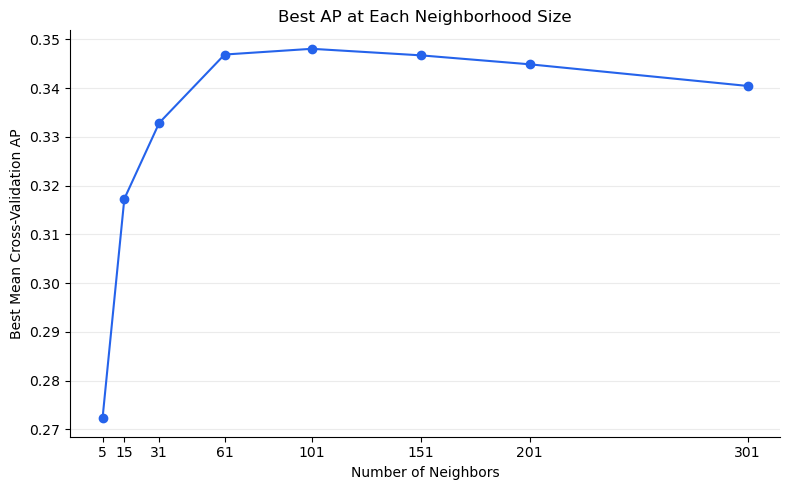


Selected search: Initial
Selected mean AP: 0.3481
The fixed test set was not used.


In [64]:
extended_param_grid = {
    "preprocessor": [
        clone(preprocessor_standard),
        clone(preprocessor_log)
    ],
    "knn__n_neighbors": [151, 201, 301],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]
}

knn_search_extended = GridSearchCV(
    estimator=clone(knn_standard),
    param_grid=extended_param_grid,
    scoring=scoring,
    refit="AP",
    cv=cv_splits,
    n_jobs=2,
    pre_dispatch=2,
    return_train_score=False,
    error_score="raise",
    verbose=1
)

knn_search_extended.fit(X_train, y_train)

extended_search_results = pd.DataFrame(
    knn_search_extended.cv_results_
)

extended_tuning_results = pd.DataFrame({
    "Candidate": extended_search_results.index,
    "Preprocessing": [
        get_preprocessing_name(preprocessor)
        for preprocessor
        in extended_search_results["param_preprocessor"]
    ],
    "Neighbors": extended_search_results[
        "param_knn__n_neighbors"
    ].astype(int),
    "Weights": extended_search_results[
        "param_knn__weights"
    ].astype(str),
    "Distance": extended_search_results["param_knn__p"].map({
        1: "Manhattan",
        2: "Euclidean"
    })
})

for metric in scoring:
    fold_columns = [
        f"split{fold}_test_{metric}"
        for fold in range(len(cv_splits))
    ]

    extended_tuning_results[f"{metric} mean"] = (
        extended_search_results[f"mean_test_{metric}"]
    )
    extended_tuning_results[f"{metric} SD"] = (
        extended_search_results[fold_columns].std(axis=1, ddof=1)
    )

combined_tuning_results = pd.concat(
    [
        tuning_results.drop(columns="AP rank").assign(
            Search="Initial"
        ),
        extended_tuning_results.assign(Search="Extended")
    ],
    ignore_index=True
)

combined_tuning_results["AP rank"] = (
    combined_tuning_results["AP mean"]
    .rank(method="min", ascending=False)
    .astype(int)
)

combined_tuning_results = combined_tuning_results.sort_values(
    "AP mean",
    ascending=False,
    kind="stable"
).reset_index(drop=True)

if knn_search_extended.best_score_ > knn_search.best_score_:
    selected_search = knn_search_extended
    selected_search_name = "Extended"
else:
    selected_search = knn_search
    selected_search_name = "Initial"

best_knn = selected_search.best_estimator_

selected_configuration = combined_tuning_results.loc[
    (
        combined_tuning_results["Search"]
        == selected_search_name
    )
    & (
        combined_tuning_results["Candidate"]
        == selected_search.best_index_
    )
].copy()

display_columns = [
    "AP rank",
    "Search",
    "Preprocessing",
    "Neighbors",
    "Weights",
    "Distance",
    "AP mean",
    "AP SD",
    "ROC_AUC mean",
    "Precision mean",
    "Recall mean",
    "F1 mean"
]

print("\nTop 10 configurations across both searches:")
display(
    combined_tuning_results[display_columns]
    .head(10)
    .round(4)
)

print("\nSelected configuration across both searches:")
display(selected_configuration.round(4))

print("\nBest mean AP at each neighborhood size:")
best_by_k = (
    combined_tuning_results
    .groupby("Neighbors")["AP mean"]
    .max()
)
display(best_by_k.to_frame().round(4))

results_dir.mkdir(parents=True, exist_ok=True)

combined_tuning_results.to_csv(
    results_dir / "knn_combined_grid_search_results.csv",
    index=False
)

selected_configuration.to_csv(
    results_dir / "knn_selected_configuration.csv",
    index=False
)

extended_search_results[fold_score_columns].rename_axis(
    "Candidate"
).to_csv(
    results_dir / "knn_extended_grid_search_fold_scores.csv"
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    best_by_k.index,
    best_by_k.values,
    marker="o",
    color="#2563EB"
)

ax.set_xlabel("Number of Neighbors")
ax.set_ylabel("Best Mean Cross-Validation AP")
ax.set_title("Best AP at Each Neighborhood Size")
ax.set_xticks(best_by_k.index)
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(
    figure_dir / "09_ap_by_neighborhood_size.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(f"\nSelected search: {selected_search_name}")
print(f"Selected mean AP: {selected_search.best_score_:.4f}")
print("The fixed test set was not used.")

### 7.Decision Threshold Selection

Selected threshold: 0.19365381

Selected threshold performance:


,Threshold,Precision,Recall,F1
5523,0.193654,0.280256,0.687418,0.398178



Pooled out-of-fold classification results:


,Precision,Recall,F1,Accuracy,Predicted purchases,TP,FP,FN,TN
Rule,,,,,,,,,
Default rule: score > 0.5,0.7059,0.0079,0.0156,0.8444,17,12,5,1514,8233
Selected rule: score >= threshold,0.2803,0.6874,0.3982,0.6752,3743,1049,2694,477,5544



Pooled out-of-fold AP: 0.3444
Pooled out-of-fold ROC-AUC: 0.7502


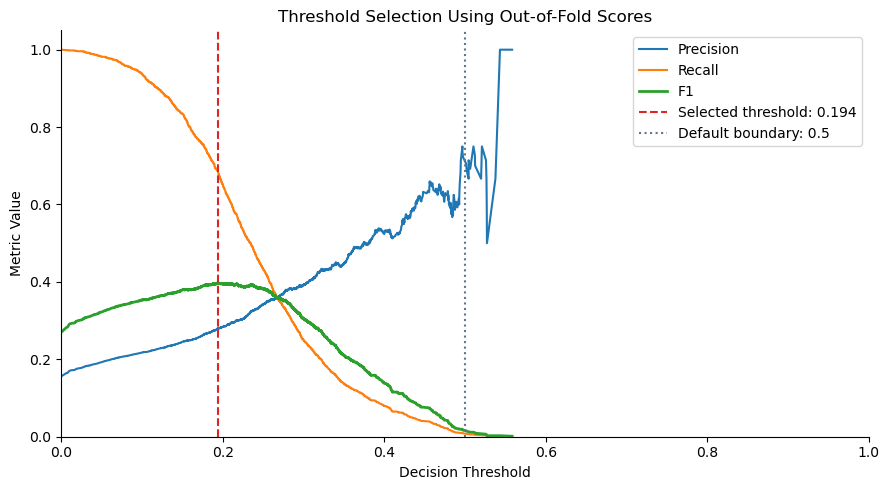


Threshold selection completed using training data only.
The fixed test set was not used.


In [67]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

oof_probabilities = cross_val_predict(
    clone(best_knn),
    X_train,
    y_train,
    cv=cv_splits,
    method="predict_proba",
    n_jobs=2
)

oof_scores = oof_probabilities[:, 1]

assert len(oof_scores) == len(y_train)
assert np.isfinite(oof_scores).all()
assert ((oof_scores >= 0) & (oof_scores <= 1)).all()

precision_values, recall_values, thresholds = precision_recall_curve(
    y_train,
    oof_scores
)

f1_values = np.divide(
    2 * precision_values[:-1] * recall_values[:-1],
    precision_values[:-1] + recall_values[:-1],
    out=np.zeros_like(thresholds),
    where=(precision_values[:-1] + recall_values[:-1]) > 0
)

threshold_results = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": precision_values[:-1],
    "Recall": recall_values[:-1],
    "F1": f1_values
})

best_threshold_index = np.flatnonzero(
    f1_values == f1_values.max()
)[-1]

selected_threshold = float(thresholds[best_threshold_index])

default_predictions = (oof_scores > 0.5).astype(int)
tuned_predictions = (oof_scores >= selected_threshold).astype(int)

comparison_rows = []

for name, predictions in [
    ("Default rule: score > 0.5", default_predictions),
    ("Selected rule: score >= threshold", tuned_predictions)
]:
    tn, fp, fn, tp = confusion_matrix(
        y_train,
        predictions,
        labels=[0, 1]
    ).ravel()

    comparison_rows.append({
        "Rule": name,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        ),
        "Accuracy": accuracy_score(y_train, predictions),
        "Predicted purchases": int(predictions.sum()),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn)
    })

threshold_comparison = pd.DataFrame(comparison_rows).set_index("Rule")

assert np.isclose(
    f1_score(y_train, tuned_predictions),
    f1_values[best_threshold_index]
)

print(f"Selected threshold: {selected_threshold:.8f}")

print("\nSelected threshold performance:")
display(
    threshold_results.iloc[[best_threshold_index]].round(6)
)

print("\nPooled out-of-fold classification results:")
display(threshold_comparison.round(4))

print(
    f"\nPooled out-of-fold AP: "
    f"{average_precision_score(y_train, oof_scores):.4f}"
)
print(
    f"Pooled out-of-fold ROC-AUC: "
    f"{roc_auc_score(y_train, oof_scores):.4f}"
)

oof_results = pd.DataFrame({
    "training_row_position": np.arange(len(X_train)),
    "validation_fold": validation_fold,
    "Revenue": y_train.to_numpy(),
    "purchase_score": oof_scores,
    "default_prediction": default_predictions,
    "selected_threshold_prediction": tuned_predictions
})

results_dir.mkdir(parents=True, exist_ok=True)

oof_results.to_csv(
    results_dir / "knn_oof_predictions.csv",
    index=False
)

threshold_results.to_csv(
    results_dir / "knn_threshold_search.csv",
    index=False
)

threshold_comparison.to_csv(
    results_dir / "knn_threshold_comparison_oof.csv"
)

pd.DataFrame({
    "Selection metric": ["Pooled OOF F1"],
    "Threshold": [selected_threshold],
    "Prediction rule": ["score >= threshold"]
}).to_csv(
    results_dir / "knn_selected_threshold.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(thresholds, precision_values[:-1], label="Precision")
ax.plot(thresholds, recall_values[:-1], label="Recall")
ax.plot(thresholds, f1_values, label="F1", linewidth=2)

ax.axvline(
    selected_threshold,
    color="#DC2626",
    linestyle="--",
    label=f"Selected threshold: {selected_threshold:.3f}"
)

ax.axvline(
    0.5,
    color="#64748B",
    linestyle=":",
    label="Default boundary: 0.5"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Decision Threshold")
ax.set_ylabel("Metric Value")
ax.set_title("Threshold Selection Using Out-of-Fold Scores")
ax.spines[["top", "right"]].set_visible(False)
ax.legend()

fig.tight_layout()
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(
    figure_dir / "10_oof_threshold_selection.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nThreshold selection completed using training data only.")
print("The fixed test set was not used.")

### 8.Sensitivity Analysis Including PageValues

#### (1) Pipeline Construction and Hyperparameter Search

In [71]:
primary_model = best_knn
primary_threshold = selected_threshold
primary_selected_configuration = selected_configuration.copy()

pv_numeric_features = main_numeric_features + ["PageValues"]
pv_log_features = log_features + ["PageValues"]
pv_features = pv_numeric_features + categorical_features

X_train_pv = train[pv_features].copy()

assert X_train_pv.index.equals(X_train.index)
assert TARGET not in X_train_pv.columns
assert X_train_pv.shape[1] == 17

pv_preprocessor_standard = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            pv_numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="drop",
    sparse_threshold=0
)

pv_preprocessor_log = ColumnTransformer(
    transformers=[
        (
            "log_numeric",
            Pipeline(
                steps=[
                    (
                        "log1p",
                        FunctionTransformer(
                            np.log1p,
                            feature_names_out="one-to-one"
                        )
                    ),
                    ("scaler", StandardScaler())
                ]
            ),
            pv_log_features
        ),
        (
            "other_numeric",
            StandardScaler(),
            remaining_numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="drop",
    sparse_threshold=0
)

pv_pipeline = Pipeline(
    steps=[
        ("preprocessor", pv_preprocessor_standard),
        (
            "knn",
            KNeighborsClassifier(
                metric="minkowski",
                algorithm="brute",
                n_jobs=1
            )
        )
    ]
)

pv_param_grid = {
    "preprocessor": [
        clone(pv_preprocessor_standard),
        clone(pv_preprocessor_log)
    ],
    "knn__n_neighbors": [5, 15, 31, 61, 101, 151, 201, 301],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]
}

pv_search = GridSearchCV(
    estimator=pv_pipeline,
    param_grid=pv_param_grid,
    scoring=scoring,
    refit="AP",
    cv=cv_splits,
    n_jobs=2,
    pre_dispatch=2,
    return_train_score=False,
    error_score="raise",
    verbose=1
)

pv_search.fit(X_train_pv, y_train)

pv_search_results = pd.DataFrame(pv_search.cv_results_)

pv_tuning_results = pd.DataFrame({
    "Candidate": pv_search_results.index,
    "AP rank": pv_search_results["rank_test_AP"],
    "Preprocessing": [
        get_preprocessing_name(preprocessor)
        for preprocessor in pv_search_results["param_preprocessor"]
    ],
    "Neighbors": pv_search_results[
        "param_knn__n_neighbors"
    ].astype(int),
    "Weights": pv_search_results["param_knn__weights"].astype(str),
    "Distance": pv_search_results["param_knn__p"].map({
        1: "Manhattan",
        2: "Euclidean"
    })
})

for metric in scoring:
    fold_columns = [
        f"split{fold}_test_{metric}"
        for fold in range(len(cv_splits))
    ]

    pv_tuning_results[f"{metric} mean"] = (
        pv_search_results[f"mean_test_{metric}"]
    )
    pv_tuning_results[f"{metric} SD"] = (
        pv_search_results[fold_columns].std(axis=1, ddof=1)
    )

pv_tuning_results = pv_tuning_results.sort_values(
    ["AP rank", "Candidate"],
    kind="stable"
).reset_index(drop=True)

pv_best_knn = pv_search.best_estimator_

pv_selected_configuration = pv_tuning_results.loc[
    pv_tuning_results["Candidate"] == pv_search.best_index_
].copy()

comparison_columns = [
    "Specification",
    "Preprocessing",
    "Neighbors",
    "Weights",
    "Distance",
    "AP mean",
    "AP SD",
    "ROC_AUC mean",
    "Precision mean",
    "Recall mean",
    "F1 mean",
    "Accuracy mean"
]

specification_comparison = pd.concat(
    [
        primary_selected_configuration.assign(
            Specification="Without PageValues"
        ),
        pv_selected_configuration.assign(
            Specification="With PageValues"
        )
    ],
    ignore_index=True
)[comparison_columns]

print("\nTop 10 configurations including PageValues:")
display(
    pv_tuning_results[
        [
            "AP rank",
            "Preprocessing",
            "Neighbors",
            "Weights",
            "Distance",
            "AP mean",
            "AP SD",
            "ROC_AUC mean",
            "Precision mean",
            "Recall mean",
            "F1 mean"
        ]
    ].head(10).round(4)
)

print("\nSelected configurations under the default decision rule:")
display(specification_comparison.round(4))

results_dir.mkdir(parents=True, exist_ok=True)

pv_tuning_results.to_csv(
    results_dir / "knn_pagevalues_grid_search_results.csv",
    index=False
)

pv_selected_configuration.to_csv(
    results_dir / "knn_pagevalues_selected_configuration.csv",
    index=False
)

specification_comparison.to_csv(
    results_dir / "knn_feature_specification_comparison_cv.csv",
    index=False
)

pv_fold_score_columns = [
    f"split{fold}_test_{metric}"
    for metric in scoring
    for fold in range(len(cv_splits))
]

pv_search_results[pv_fold_score_columns].rename_axis(
    "Candidate"
).to_csv(
    results_dir / "knn_pagevalues_grid_search_fold_scores.csv"
)

print("\nPageValues sensitivity search completed.")
print(f"Primary threshold preserved: {primary_threshold:.8f}")
print("The comparison uses default classification rules.")
print("The PageValues model threshold has not yet been selected.")
print("The fixed test set was not used.")

Fitting 5 folds for each of 64 candidates, totalling 320 fits

Top 10 configurations including PageValues:


,AP rank,Preprocessing,Neighbors,Weights,Distance,AP mean,AP SD,ROC_AUC mean,Precision mean,Recall mean,F1 mean
0,1,Log1p + Standard,31,distance,Euclidean,0.7155,0.0332,0.9126,0.7231,0.5354,0.6151
1,2,Log1p + Standard,61,distance,Euclidean,0.7145,0.0333,0.9148,0.7359,0.4954,0.5919
2,3,Log1p + Standard,101,distance,Euclidean,0.7102,0.0356,0.9143,0.7410,0.4810,0.5829
3,4,Log1p + Standard,151,distance,Euclidean,0.7089,0.0341,0.9144,0.7506,0.4614,0.5707
4,5,Log1p + Standard,201,distance,Euclidean,0.7072,0.0335,0.9135,0.7478,0.4424,0.5554
5,6,Log1p + Standard,61,uniform,Euclidean,0.7055,0.0330,0.9137,0.7374,0.4928,0.5905
6,7,Log1p + Standard,151,uniform,Euclidean,0.7036,0.0342,0.9134,0.7514,0.4542,0.5655
7,8,Log1p + Standard,101,uniform,Euclidean,0.7035,0.0355,0.9131,0.7409,0.4751,0.5785
8,9,Log1p + Standard,201,uniform,Euclidean,0.7027,0.0336,0.9125,0.7500,0.4391,0.5534
9,10,Log1p + Standard,31,uniform,Euclidean,0.7021,0.0327,0.9112,0.7227,0.5354,0.6149



Selected configurations under the default decision rule:


,Specification,Preprocessing,Neighbors,Weights,Distance,AP mean,AP SD,ROC_AUC mean,Precision mean,Recall mean,F1 mean,Accuracy mean
0,Without PageValues,Log1p + Standard,101,distance,Manhattan,0.3481,0.0259,0.7506,0.7643,0.0079,0.0155,0.8444
1,With PageValues,Log1p + Standard,31,distance,Euclidean,0.7155,0.0332,0.9126,0.7231,0.5354,0.6151,0.8953



PageValues sensitivity search completed.
Primary threshold preserved: 0.19365381
The comparison uses default classification rules.
The PageValues model threshold has not yet been selected.
The fixed test set was not used.


#### (2)Threshold Selection for the PageValues Model

Primary model threshold: 0.19365381
PageValues model threshold: 0.35857186

Selected PageValues threshold performance:


,Threshold,Precision,Recall,F1
4644,0.358572,0.648799,0.690039,0.668784



Pooled out-of-fold performance:


,Specification,Rule,Threshold,AP,ROC_AUC,Precision,Recall,F1,Accuracy
0,Without PageValues,Default: score > 0.5,0.5000,0.3444,0.7502,0.7059,0.0079,0.0156,0.8444
1,Without PageValues,Selected: score >= threshold,0.1937,0.3444,0.7502,0.2803,0.6874,0.3982,0.6752
2,With PageValues,Default: score > 0.5,0.5000,0.7140,0.9127,0.7230,0.5354,0.6152,0.8953
3,With PageValues,Selected: score >= threshold,0.3586,0.7140,0.9127,0.6488,0.6900,0.6688,0.8932



Pooled out-of-fold classification counts:


,Specification,Rule,Predicted purchases,TP,FP,FN,TN
0,Without PageValues,Default: score > 0.5,17,12,5,1514,8233
1,Without PageValues,Selected: score >= threshold,3743,1049,2694,477,5544
2,With PageValues,Default: score > 0.5,1130,817,313,709,7925
3,With PageValues,Selected: score >= threshold,1623,1053,570,473,7668


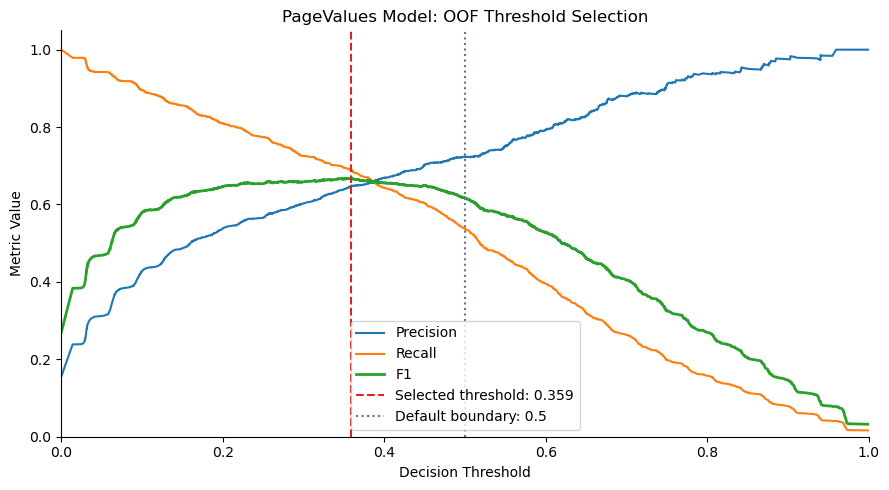


Both model thresholds have been selected.
The primary model and its threshold remain unchanged.
The fixed test set was not used.


In [74]:
pv_oof_probabilities = cross_val_predict(
    clone(pv_best_knn),
    X_train_pv,
    y_train,
    cv=cv_splits,
    method="predict_proba",
    n_jobs=2
)

pv_oof_scores = pv_oof_probabilities[:, 1]

assert len(pv_oof_scores) == len(y_train)
assert np.isfinite(pv_oof_scores).all()
assert ((pv_oof_scores >= 0) & (pv_oof_scores <= 1)).all()

pv_precision, pv_recall, pv_thresholds = precision_recall_curve(
    y_train,
    pv_oof_scores
)

pv_f1 = np.divide(
    2 * pv_precision[:-1] * pv_recall[:-1],
    pv_precision[:-1] + pv_recall[:-1],
    out=np.zeros_like(pv_thresholds),
    where=(pv_precision[:-1] + pv_recall[:-1]) > 0
)

pv_threshold_results = pd.DataFrame({
    "Threshold": pv_thresholds,
    "Precision": pv_precision[:-1],
    "Recall": pv_recall[:-1],
    "F1": pv_f1
})

pv_best_threshold_index = np.flatnonzero(
    pv_f1 == pv_f1.max()
)[-1]

pv_selected_threshold = float(
    pv_thresholds[pv_best_threshold_index]
)

pv_default_predictions = (pv_oof_scores > 0.5).astype(int)
pv_tuned_predictions = (
    pv_oof_scores >= pv_selected_threshold
).astype(int)

assert np.isclose(
    f1_score(y_train, pv_tuned_predictions),
    pv_f1[pv_best_threshold_index]
)

comparison_rows = []

for specification, scores, threshold in [
    ("Without PageValues", oof_scores, primary_threshold),
    ("With PageValues", pv_oof_scores, pv_selected_threshold)
]:
    for rule, predictions, boundary in [
        ("Default: score > 0.5", (scores > 0.5).astype(int), 0.5),
        (
            "Selected: score >= threshold",
            (scores >= threshold).astype(int),
            threshold
        )
    ]:
        tn, fp, fn, tp = confusion_matrix(
            y_train,
            predictions,
            labels=[0, 1]
        ).ravel()

        comparison_rows.append({
            "Specification": specification,
            "Rule": rule,
            "Threshold": boundary,
            "AP": average_precision_score(y_train, scores),
            "ROC_AUC": roc_auc_score(y_train, scores),
            "Precision": precision_score(
                y_train, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_train, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_train, predictions, zero_division=0
            ),
            "Accuracy": accuracy_score(y_train, predictions),
            "Predicted purchases": int(predictions.sum()),
            "TP": int(tp),
            "FP": int(fp),
            "FN": int(fn),
            "TN": int(tn)
        })

oof_specification_comparison = pd.DataFrame(comparison_rows)

print(f"Primary model threshold: {primary_threshold:.8f}")
print(f"PageValues model threshold: {pv_selected_threshold:.8f}")

print("\nSelected PageValues threshold performance:")
display(
    pv_threshold_results.iloc[[pv_best_threshold_index]].round(6)
)

print("\nPooled out-of-fold performance:")
display(
    oof_specification_comparison[
        [
            "Specification",
            "Rule",
            "Threshold",
            "AP",
            "ROC_AUC",
            "Precision",
            "Recall",
            "F1",
            "Accuracy"
        ]
    ].round(4)
)

print("\nPooled out-of-fold classification counts:")
display(
    oof_specification_comparison[
        [
            "Specification",
            "Rule",
            "Predicted purchases",
            "TP",
            "FP",
            "FN",
            "TN"
        ]
    ]
)

pv_oof_results = pd.DataFrame({
    "training_row_position": np.arange(len(X_train_pv)),
    "validation_fold": validation_fold,
    "Revenue": y_train.to_numpy(),
    "purchase_score": pv_oof_scores,
    "default_prediction": pv_default_predictions,
    "selected_threshold_prediction": pv_tuned_predictions
})

results_dir.mkdir(parents=True, exist_ok=True)

pv_oof_results.to_csv(
    results_dir / "knn_pagevalues_oof_predictions.csv",
    index=False
)

pv_threshold_results.to_csv(
    results_dir / "knn_pagevalues_threshold_search.csv",
    index=False
)

oof_specification_comparison.to_csv(
    results_dir / "knn_both_specifications_oof_comparison.csv",
    index=False
)

pd.DataFrame({
    "Selection metric": ["Pooled OOF F1"],
    "Threshold": [pv_selected_threshold],
    "Prediction rule": ["score >= threshold"]
}).to_csv(
    results_dir / "knn_pagevalues_selected_threshold.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(pv_thresholds, pv_precision[:-1], label="Precision")
ax.plot(pv_thresholds, pv_recall[:-1], label="Recall")
ax.plot(pv_thresholds, pv_f1, label="F1", linewidth=2)

ax.axvline(
    pv_selected_threshold,
    color="#DC2626",
    linestyle="--",
    label=f"Selected threshold: {pv_selected_threshold:.3f}"
)

ax.axvline(
    0.5,
    color="#64748B",
    linestyle=":",
    label="Default boundary: 0.5"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Decision Threshold")
ax.set_ylabel("Metric Value")
ax.set_title("PageValues Model: OOF Threshold Selection")
ax.spines[["top", "right"]].set_visible(False)
ax.legend()

fig.tight_layout()
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(
    figure_dir / "11_pagevalues_oof_threshold_selection.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nBoth model thresholds have been selected.")
print("The primary model and its threshold remain unchanged.")
print("The fixed test set was not used.")

### 9.Final Training, Held-Out Test Evaluation and Test Results

Test sessions: 2,441
Test purchases: 382
Test purchase rate: 15.65%
All-negative test accuracy: 84.35%

Held-out test metrics:


,Specification,Rule,Threshold,AP,ROC_AUC,Precision,Recall,F1,Accuracy
0,Without PageValues,Default,0.5000,0.3461,0.7660,0.8571,0.0157,0.0308,0.8456
1,Without PageValues,Selected threshold,0.1937,0.3461,0.7660,0.2933,0.6911,0.4119,0.6911
2,With PageValues,Default,0.5000,0.7176,0.9162,0.7186,0.5550,0.6263,0.8964
3,With PageValues,Selected threshold,0.3586,0.7176,0.9162,0.6272,0.7356,0.6771,0.8902



Held-out test classification counts:


,Specification,Rule,Predicted purchases,TP,FP,FN,TN
0,Without PageValues,Default,7,6,1,376,2058
1,Without PageValues,Selected threshold,900,264,636,118,1423
2,With PageValues,Default,295,212,83,170,1976
3,With PageValues,Selected threshold,448,281,167,101,1892


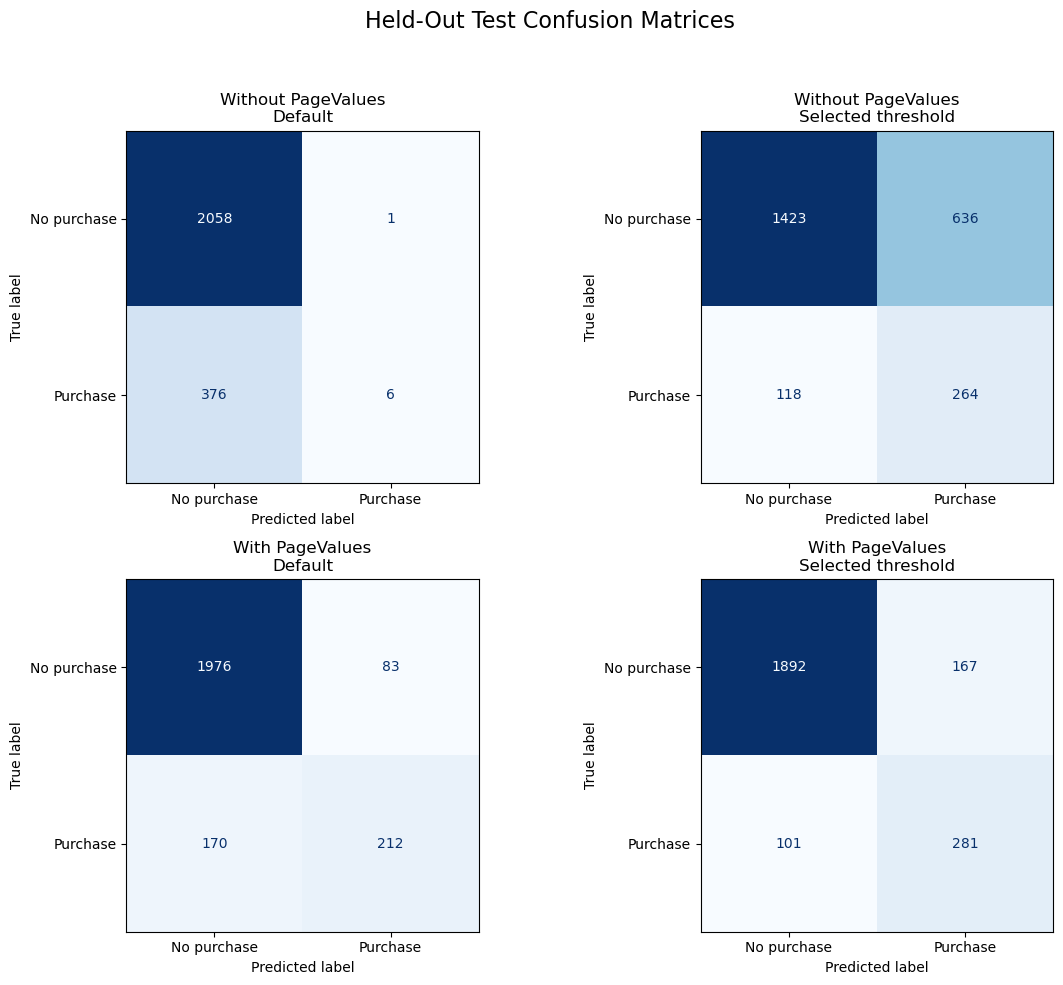

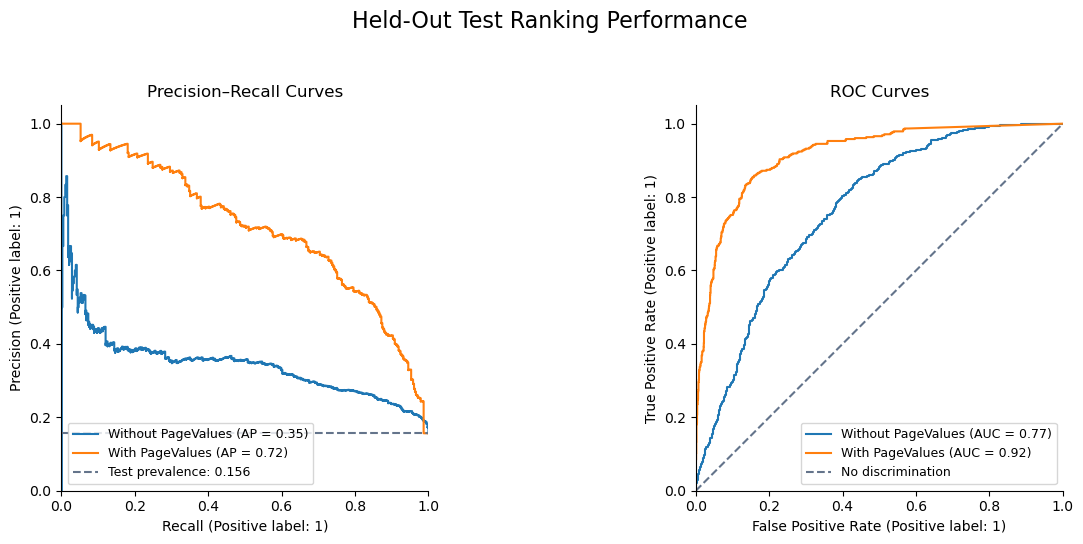


Final test evaluation completed.
All parameters and thresholds were selected using training data.


In [77]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay
)

X_test_pv = test[pv_features].copy()

assert X_train.columns.equals(X_test.columns)
assert X_train_pv.columns.equals(X_test_pv.columns)
assert X_test.index.equals(y_test.index)
assert X_test_pv.index.equals(y_test.index)

final_primary_model = clone(primary_model)
final_pv_model = clone(pv_best_knn)

final_primary_model.fit(X_train, y_train)
final_pv_model.fit(X_train_pv, y_train)

primary_positive_column = np.flatnonzero(
    final_primary_model.classes_ == 1
)[0]

pv_positive_column = np.flatnonzero(
    final_pv_model.classes_ == 1
)[0]

primary_test_scores = final_primary_model.predict_proba(
    X_test
)[:, primary_positive_column]

pv_test_scores = final_pv_model.predict_proba(
    X_test_pv
)[:, pv_positive_column]

test_score_sets = {
    "Without PageValues": (
        primary_test_scores,
        primary_threshold
    ),
    "With PageValues": (
        pv_test_scores,
        pv_selected_threshold
    )
}

test_rows = []
test_prediction_sets = {}

for specification, (scores, threshold) in test_score_sets.items():
    assert np.isfinite(scores).all()
    assert ((scores >= 0) & (scores <= 1)).all()

    for rule, predictions, boundary in [
        (
            "Default",
            (scores > 0.5).astype(int),
            0.5
        ),
        (
            "Selected threshold",
            (scores >= threshold).astype(int),
            threshold
        )
    ]:
        tn, fp, fn, tp = confusion_matrix(
            y_test,
            predictions,
            labels=[0, 1]
        ).ravel()

        test_prediction_sets[(specification, rule)] = predictions

        test_rows.append({
            "Specification": specification,
            "Rule": rule,
            "Threshold": boundary,
            "AP": average_precision_score(y_test, scores),
            "ROC_AUC": roc_auc_score(y_test, scores),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_test, predictions, zero_division=0
            ),
            "Accuracy": accuracy_score(y_test, predictions),
            "Predicted purchases": int(predictions.sum()),
            "TP": int(tp),
            "FP": int(fp),
            "FN": int(fn),
            "TN": int(tn)
        })

test_results = pd.DataFrame(test_rows)

print(f"Test sessions: {len(y_test):,}")
print(f"Test purchases: {int(y_test.sum()):,}")
print(f"Test purchase rate: {y_test.mean():.2%}")
print(
    f"All-negative test accuracy: "
    f"{(y_test == 0).mean():.2%}"
)

print("\nHeld-out test metrics:")
display(
    test_results[
        [
            "Specification",
            "Rule",
            "Threshold",
            "AP",
            "ROC_AUC",
            "Precision",
            "Recall",
            "F1",
            "Accuracy"
        ]
    ].round(4)
)

print("\nHeld-out test classification counts:")
display(
    test_results[
        [
            "Specification",
            "Rule",
            "Predicted purchases",
            "TP",
            "FP",
            "FN",
            "TN"
        ]
    ]
)

test_predictions = pd.DataFrame({
    "test_row_position": np.arange(len(y_test)),
    "Revenue": y_test.to_numpy(),
    "primary_score": primary_test_scores,
    "primary_default_prediction": test_prediction_sets[
        ("Without PageValues", "Default")
    ],
    "primary_selected_prediction": test_prediction_sets[
        ("Without PageValues", "Selected threshold")
    ],
    "pagevalues_score": pv_test_scores,
    "pagevalues_default_prediction": test_prediction_sets[
        ("With PageValues", "Default")
    ],
    "pagevalues_selected_prediction": test_prediction_sets[
        ("With PageValues", "Selected threshold")
    ]
})

results_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)

test_results.to_csv(
    results_dir / "knn_final_test_results.csv",
    index=False
)

test_predictions.to_csv(
    results_dir / "knn_final_test_predictions.csv",
    index=False
)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for row, specification in enumerate(test_score_sets):
    for col, rule in enumerate(["Default", "Selected threshold"]):
        predictions = test_prediction_sets[(specification, rule)]

        ConfusionMatrixDisplay.from_predictions(
            y_test,
            predictions,
            labels=[0, 1],
            display_labels=["No purchase", "Purchase"],
            cmap="Blues",
            colorbar=False,
            values_format="d",
            ax=axes[row, col]
        )

        axes[row, col].set_title(f"{specification}\n{rule}")

fig.suptitle("Held-Out Test Confusion Matrices", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(
    figure_dir / "12_test_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for specification, (scores, threshold) in test_score_sets.items():
    PrecisionRecallDisplay.from_predictions(
        y_test,
        scores,
        name=specification,
        ax=axes[0]
    )

    RocCurveDisplay.from_predictions(
        y_test,
        scores,
        name=specification,
        ax=axes[1]
    )

axes[0].axhline(
    y_test.mean(),
    color="#64748B",
    linestyle="--",
    label=f"Test prevalence: {y_test.mean():.3f}"
)

axes[1].plot(
    [0, 1],
    [0, 1],
    color="#64748B",
    linestyle="--",
    label="No discrimination"
)

axes[0].set_title("Precision–Recall Curves")
axes[1].set_title("ROC Curves")

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=9)

fig.suptitle("Held-Out Test Ranking Performance", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(
    figure_dir / "13_test_pr_roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nFinal test evaluation completed.")
print("All parameters and thresholds were selected using training data.")